In [32]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder

# Load the data
df = pd.read_csv('Angry+Birds+(Cardinal+Personalities)+Data+for+assignment.csv')

# Create a label encoder object
encoder = LabelEncoder()

# Encode the categorical columns
df['Month'] = encoder.fit_transform(df['Month'])
df['Habitat'] = encoder.fit_transform(df['Habitat'])
df['Site'] = encoder.fit_transform(df['Site'])
df['Location'] = encoder.fit_transform(df['Location'])
df['Sex'] = encoder.fit_transform(df['Sex'])
df['Personality'] = encoder.fit_transform(df['Personality'])

# Select all columns except 'Personality' for clustering
X = df.drop(columns=['Personality'])

# Create the k-means model with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42)

# Fit the model to the data
kmeans.fit(X)

# Get the cluster labels for each data point
labels = kmeans.labels_

# Add the cluster labels to the original DataFrame
df['Cluster'] = labels

# Print the updated DataFrame
print(df)


    Month  Habitat  Site  Location  Sex  SexID  Weight  WingL  TarsusL  CORT1  \
0       2        0     1         1    1      2      35    9.1    21.76   5.23   
1       6        1     0         2    0      1      37    8.4    20.09   3.05   
2       2        1     1         3    0      1      37    8.6    19.50   8.73   
3       1        0     0         0    0      1      37    8.4    19.36  11.11   
4       4        1     0         2    0      1      38    8.4    19.01   1.33   
..    ...      ...   ...       ...  ...    ...     ...    ...      ...    ...   
62      5        1     0         2    1      2      45    8.6    20.29   0.50   
63      5        0     0         0    0      1      45    9.0    20.87   7.67   
64      1        1     1         3    1      2      46    9.1    21.23   1.46   
65      2        1     1         3    1      2      46    8.9    21.33   4.65   
66      3        0     1         1    1      2      48    9.2    21.81   0.54   

    CORT2  CORT3  Explorati

Check Correlation

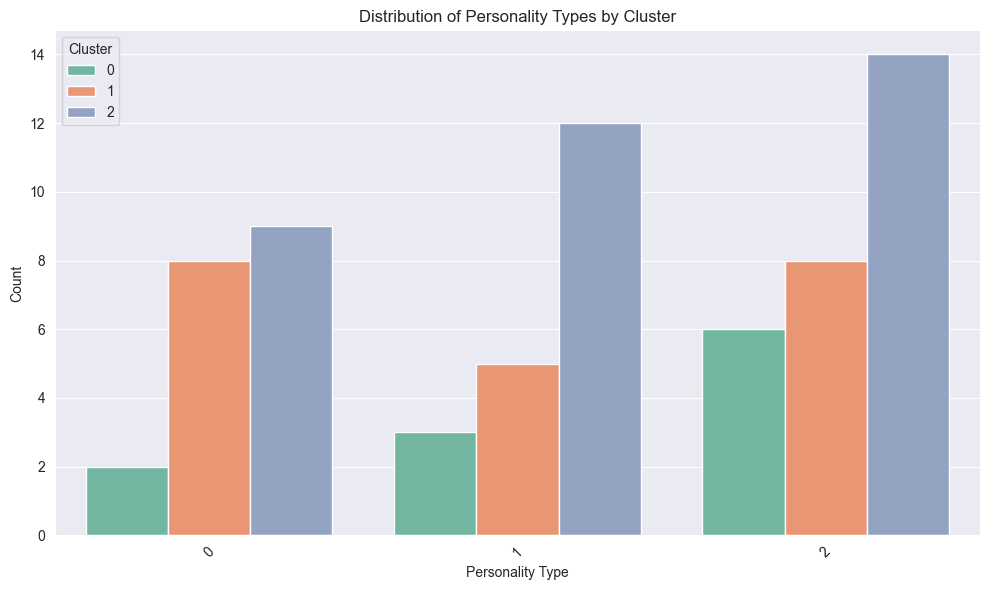

In [33]:
import seaborn as sns
# Create a count plot to visualize the distribution of personality types across clusters
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Personality', hue='Cluster', palette='Set2')

# Adding title and labels
plt.title('Distribution of Personality Types by Cluster')
plt.xlabel('Personality Type')
plt.ylabel('Count')
plt.legend(title='Cluster')
plt.xticks(rotation=45)
plt.tight_layout()

# Show the plot
plt.show()


Visualise correlation

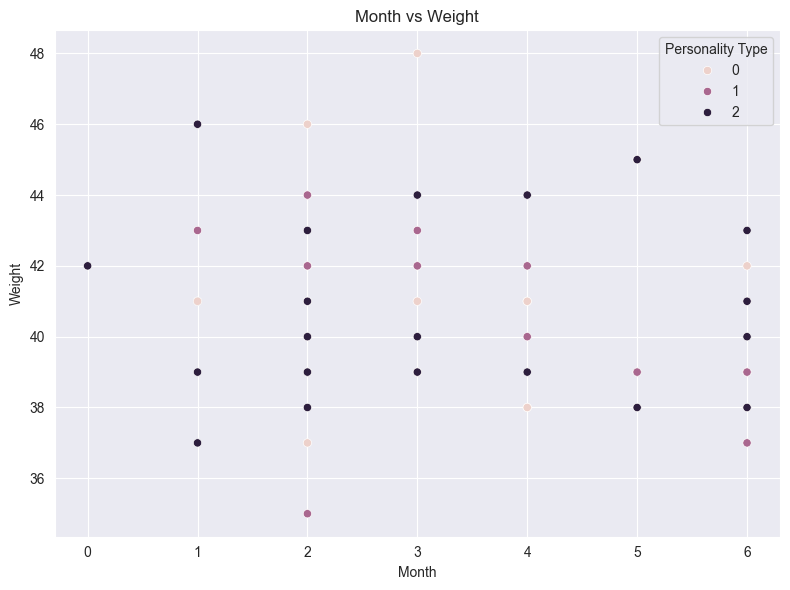

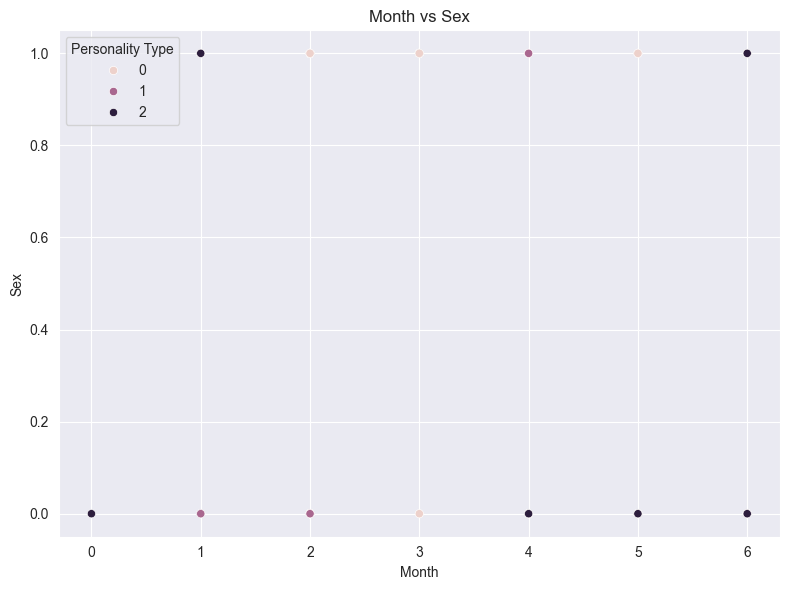

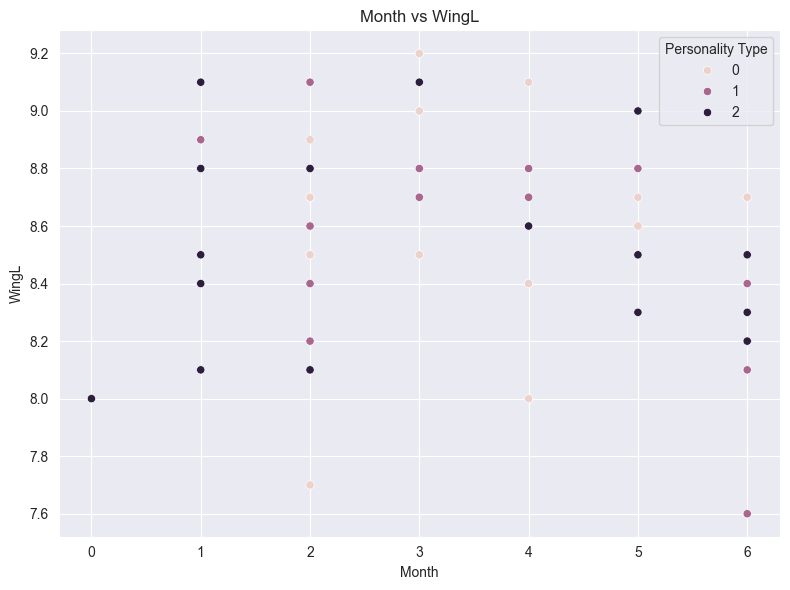

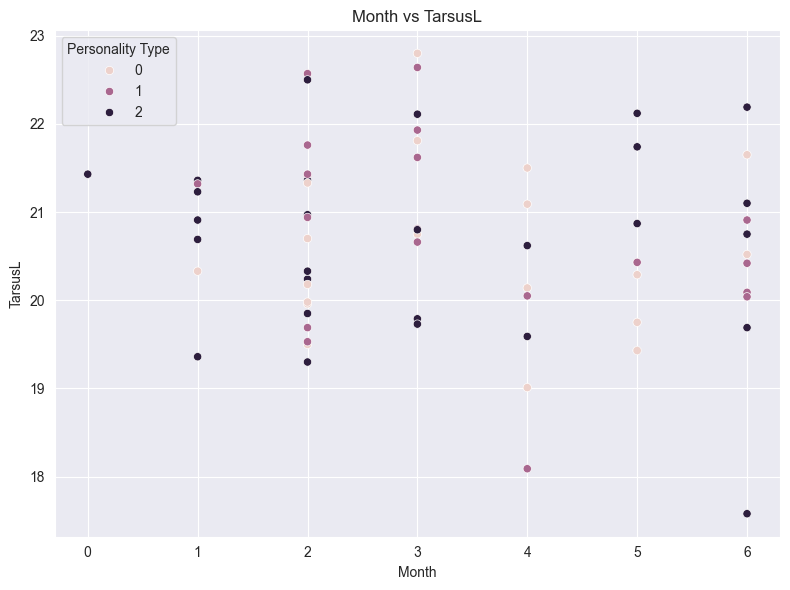

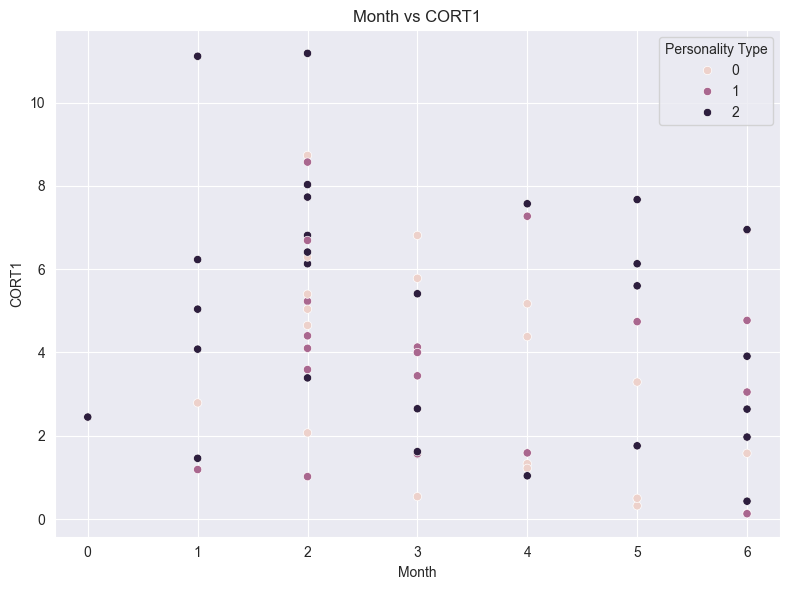

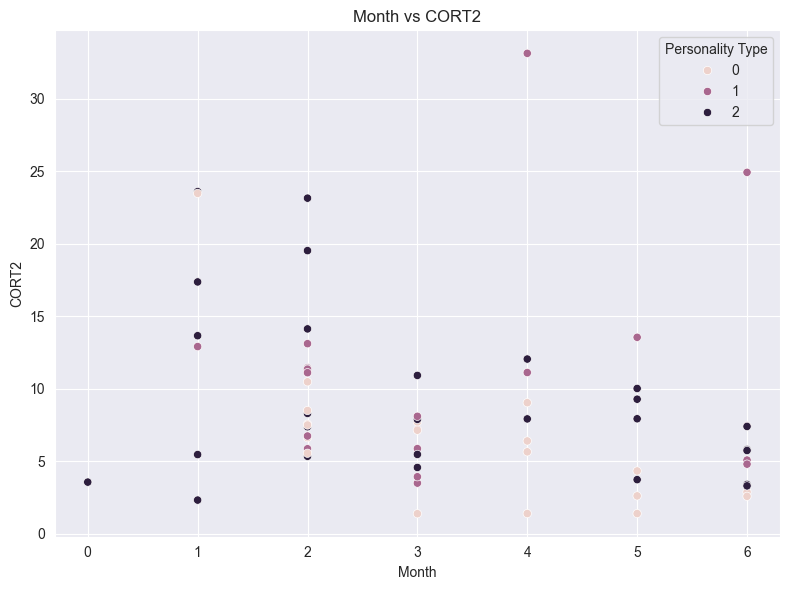

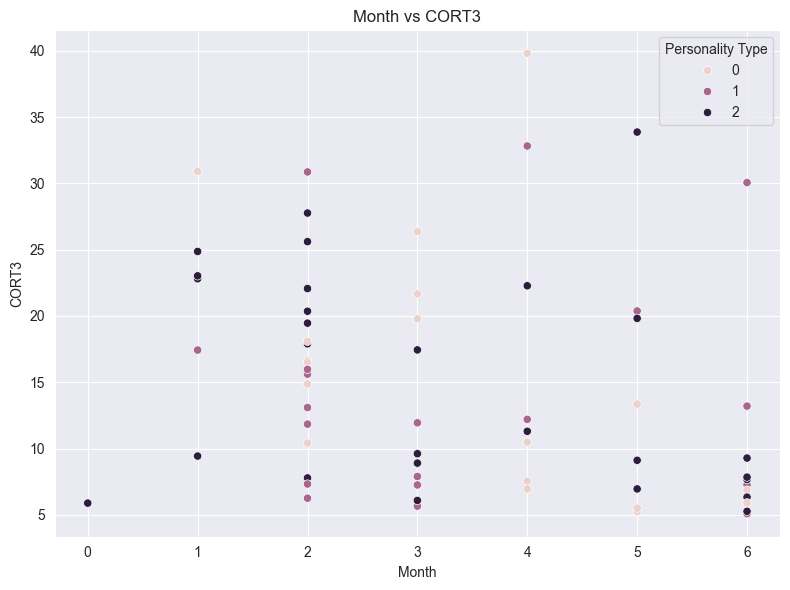

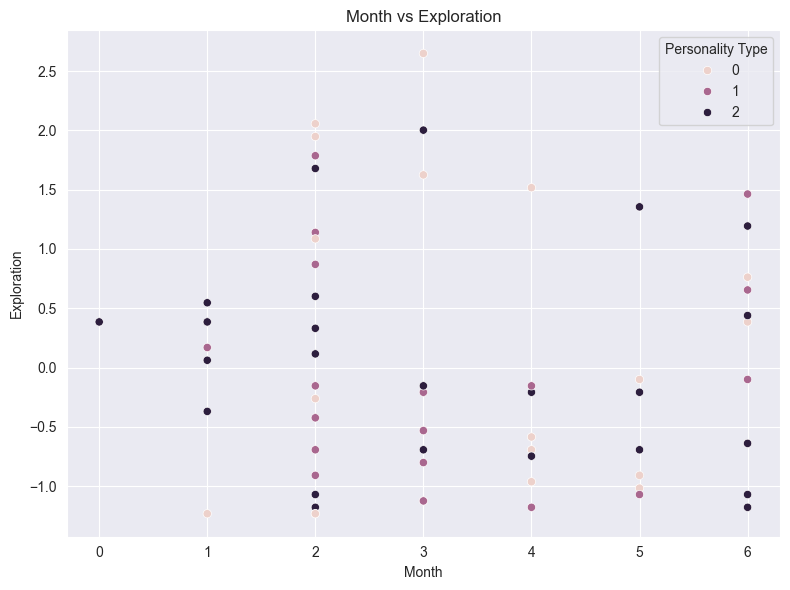

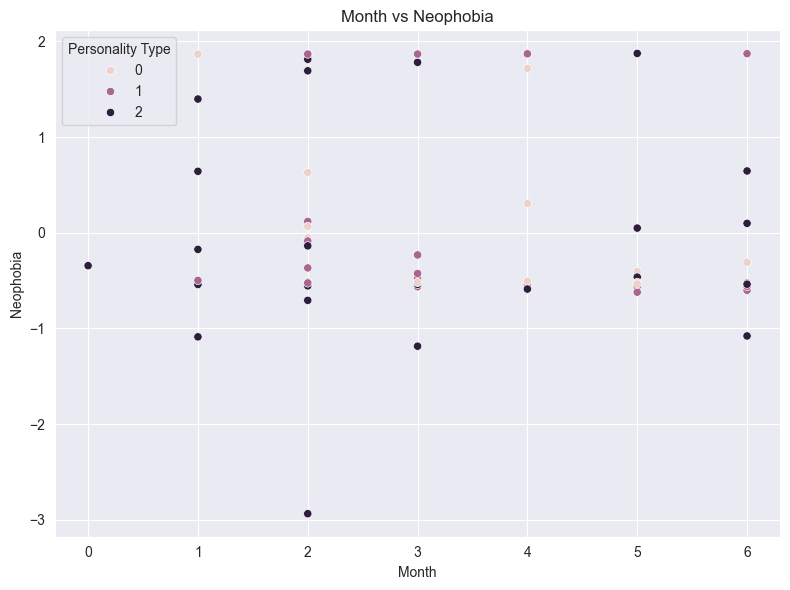

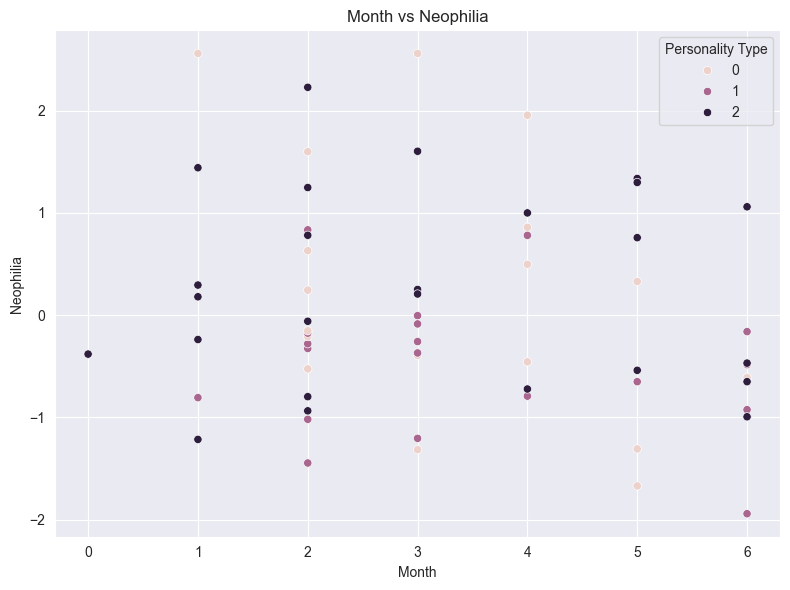

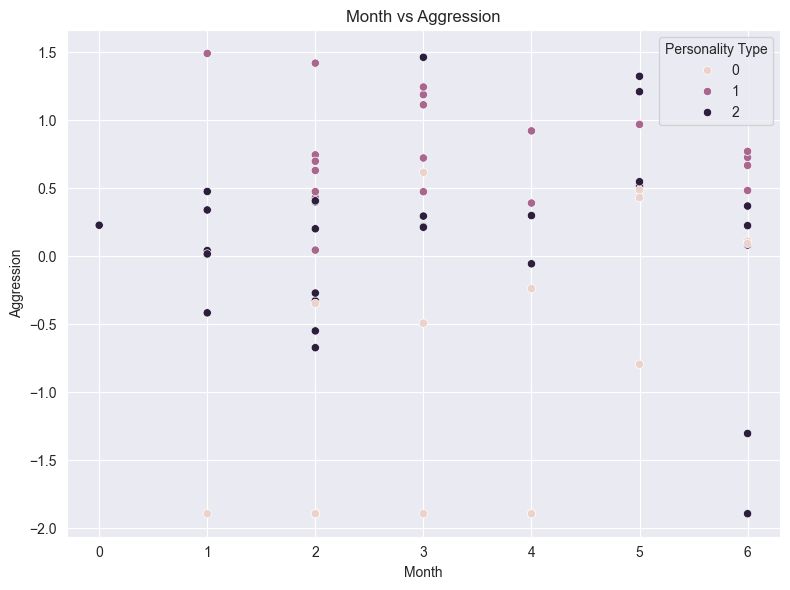

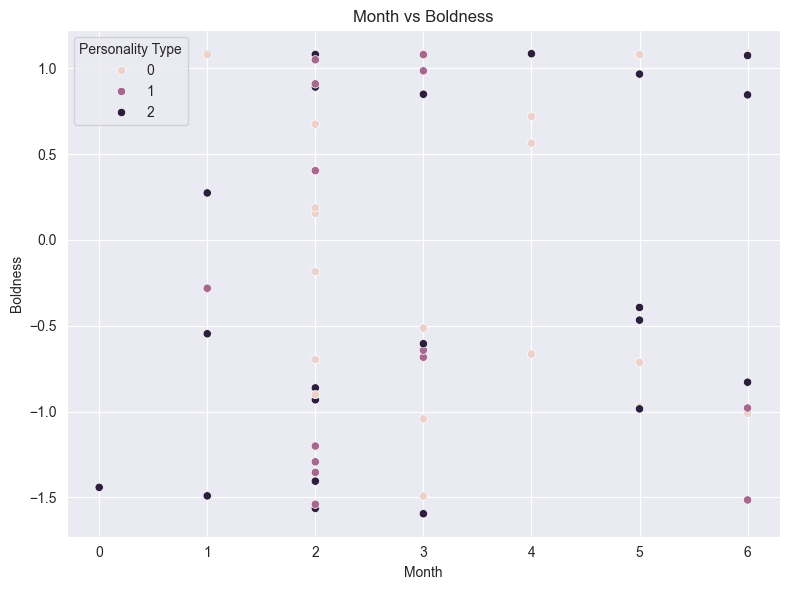

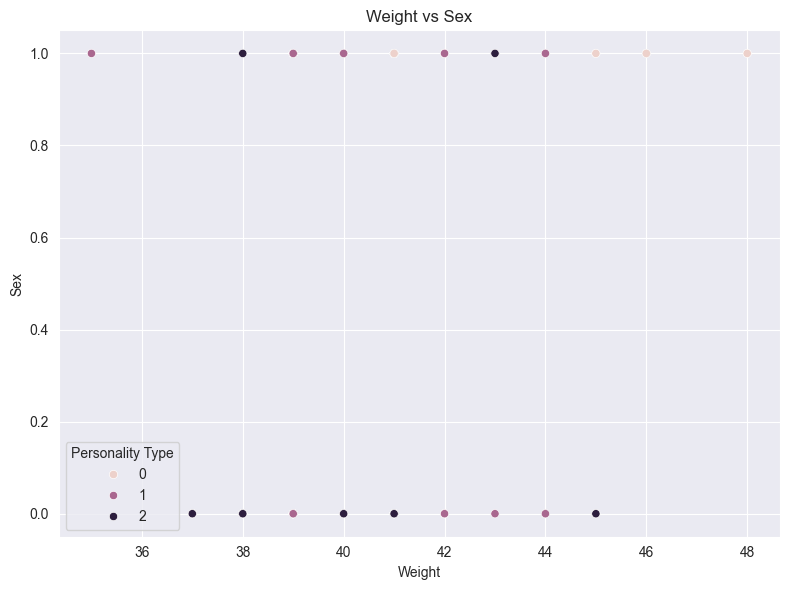

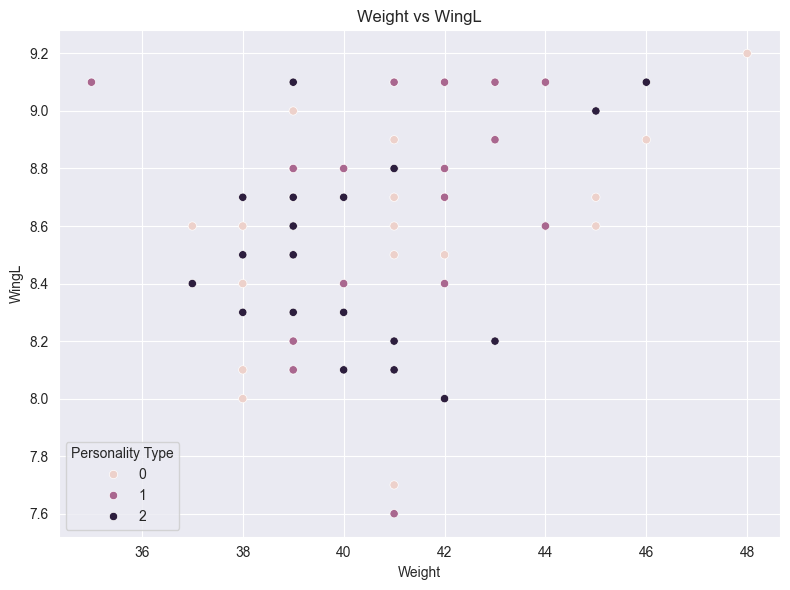

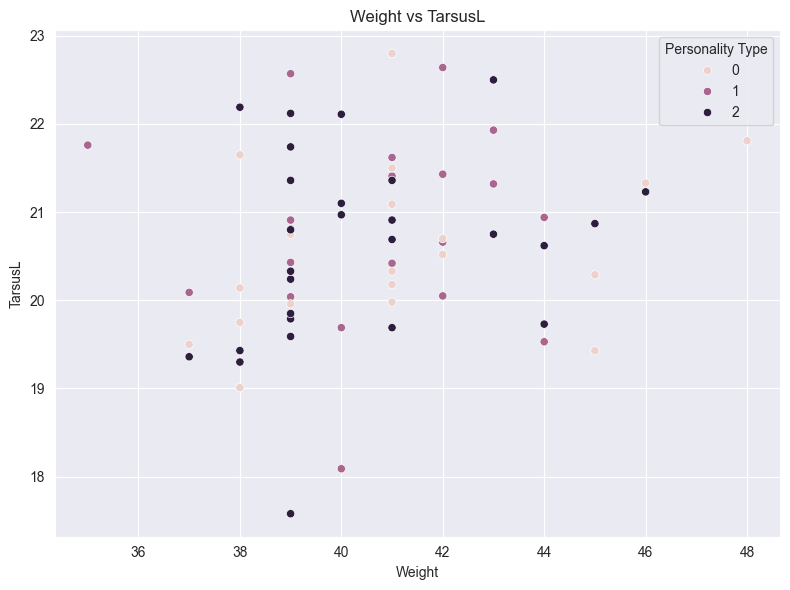

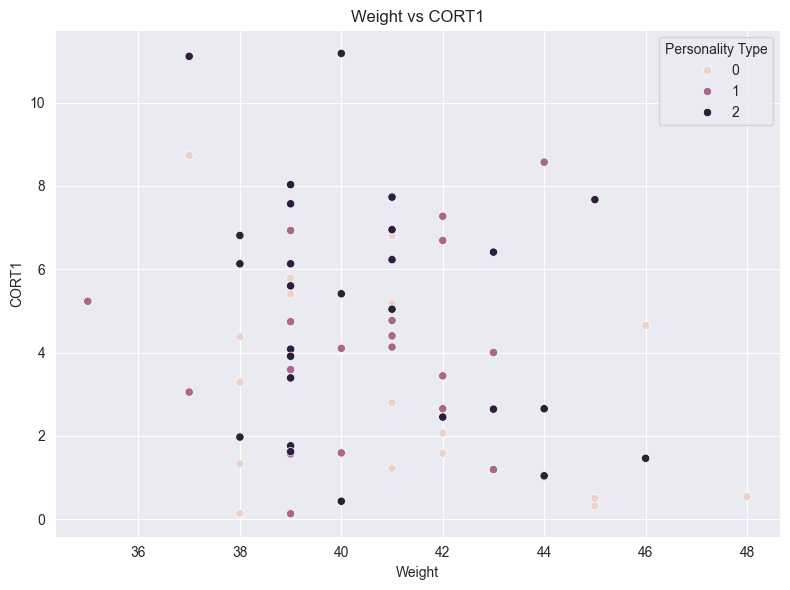

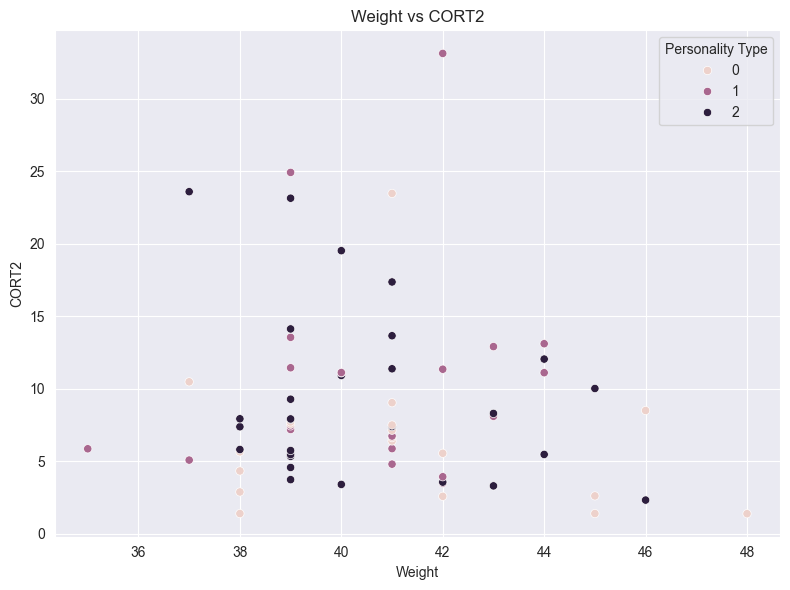

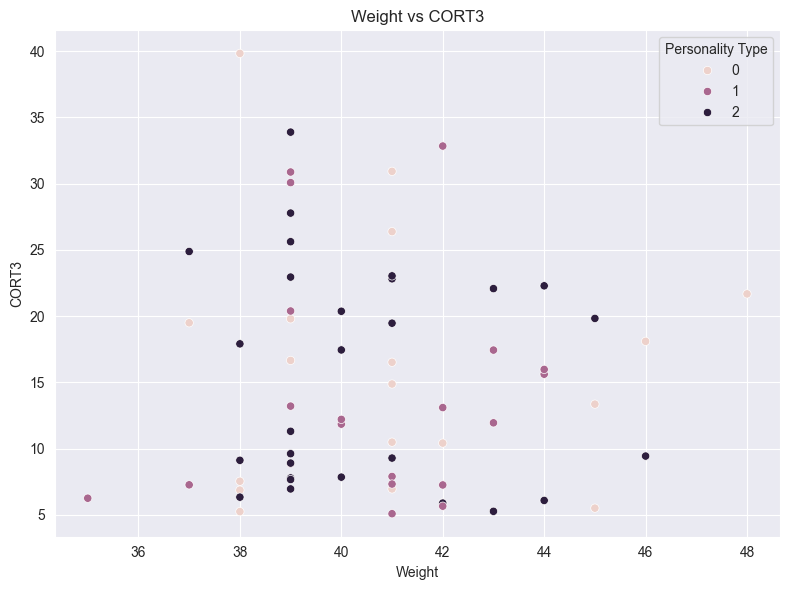

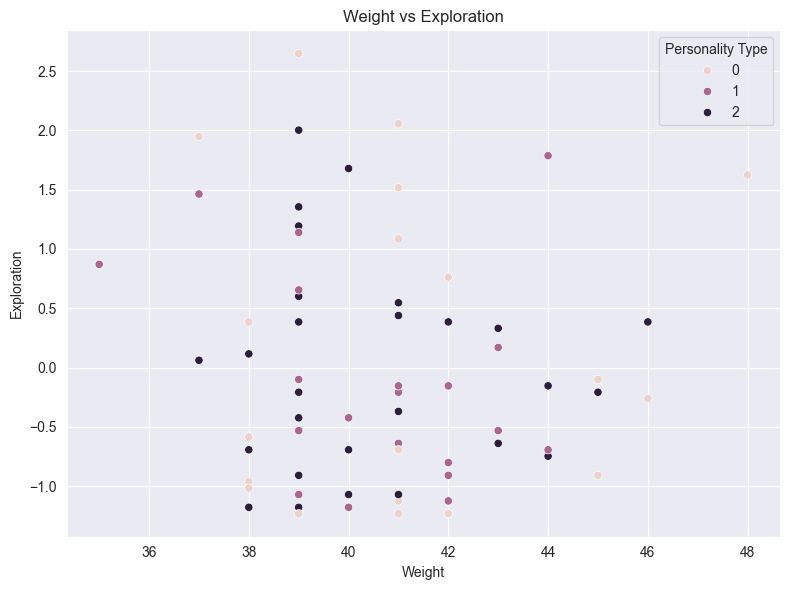

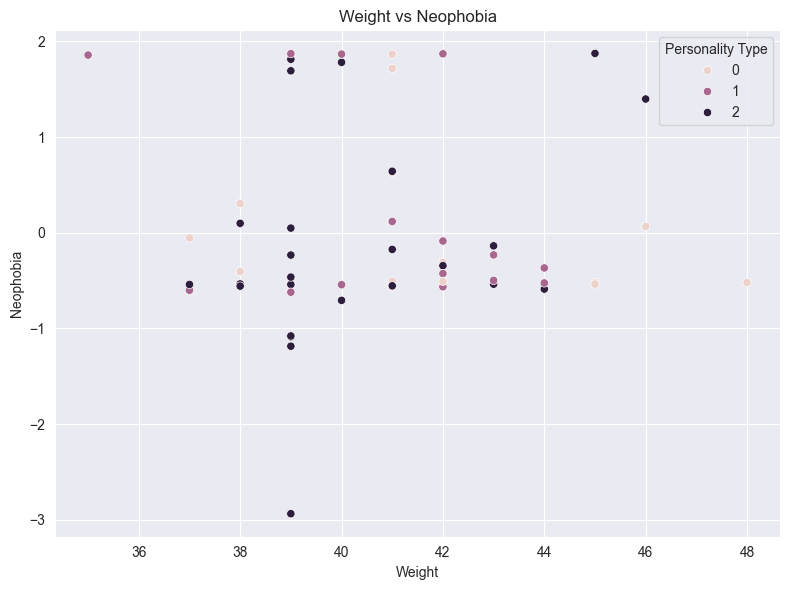

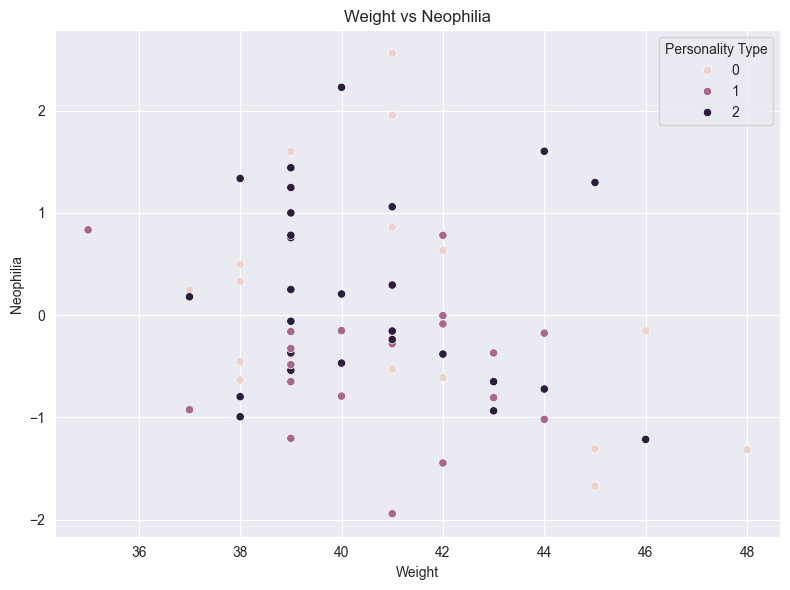

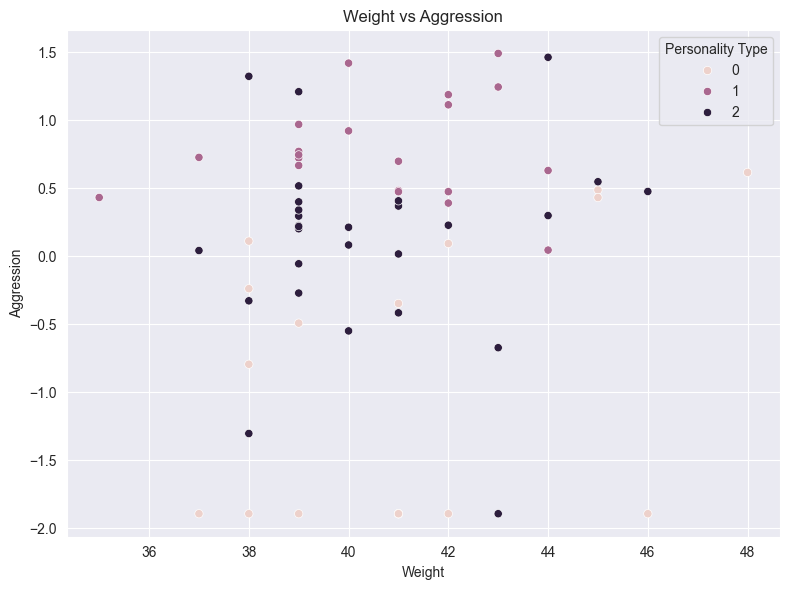

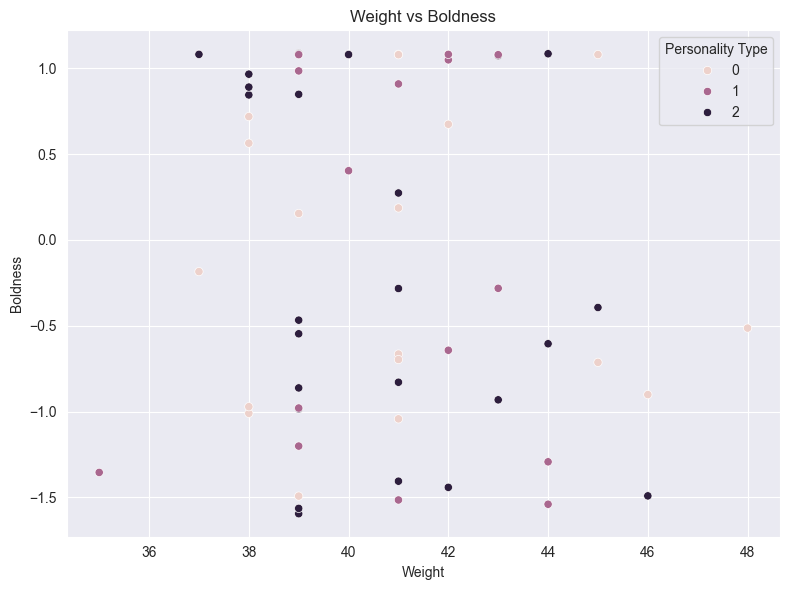

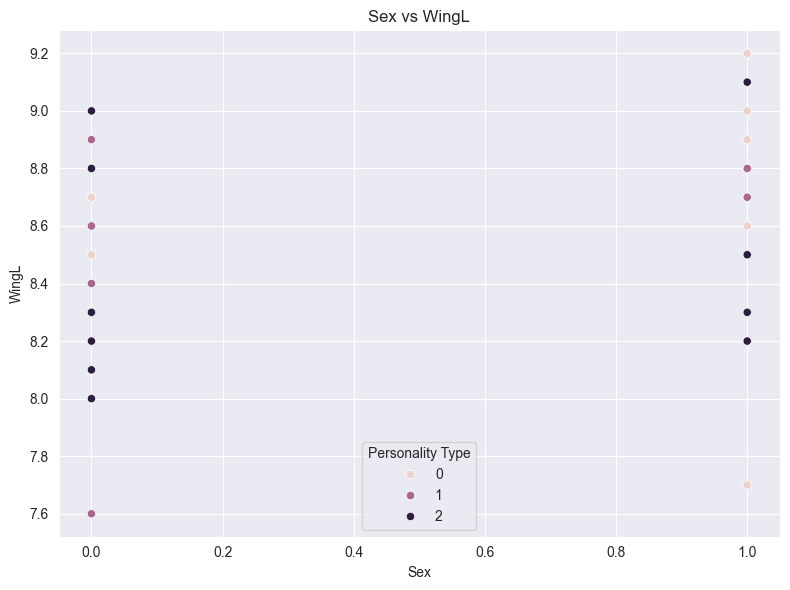

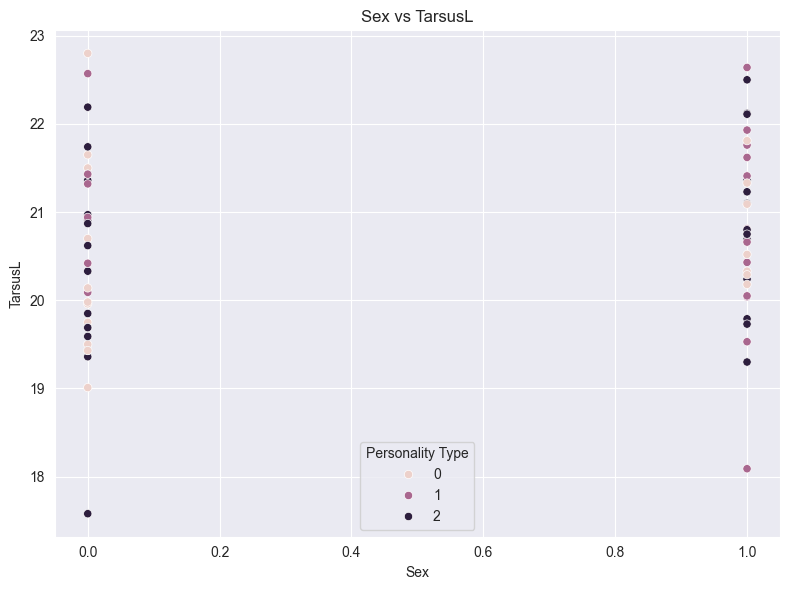

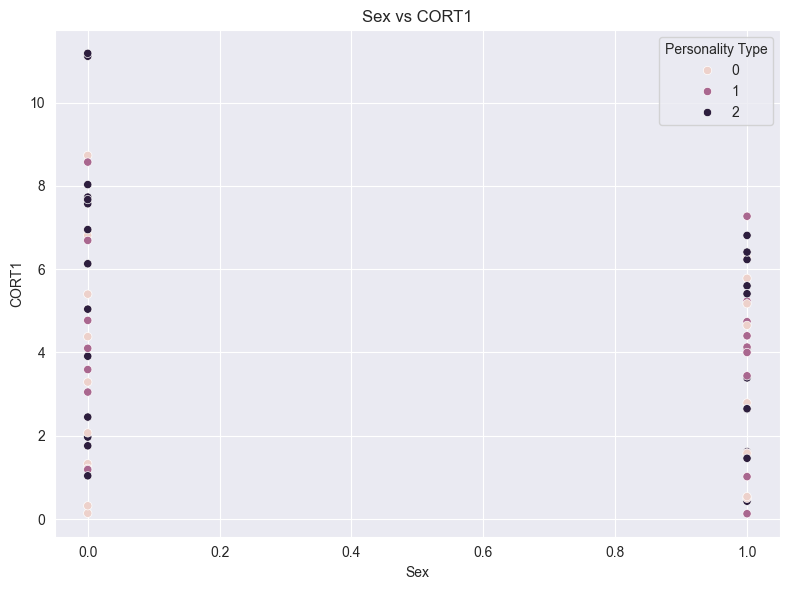

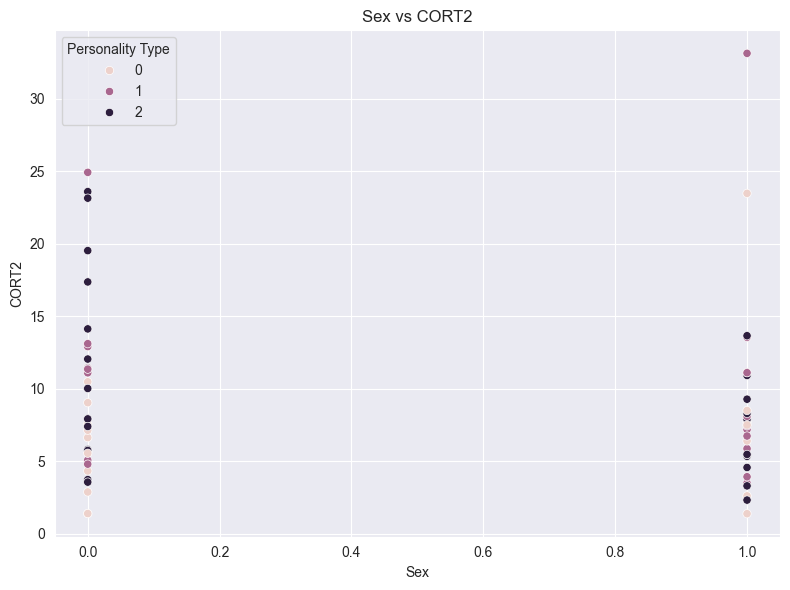

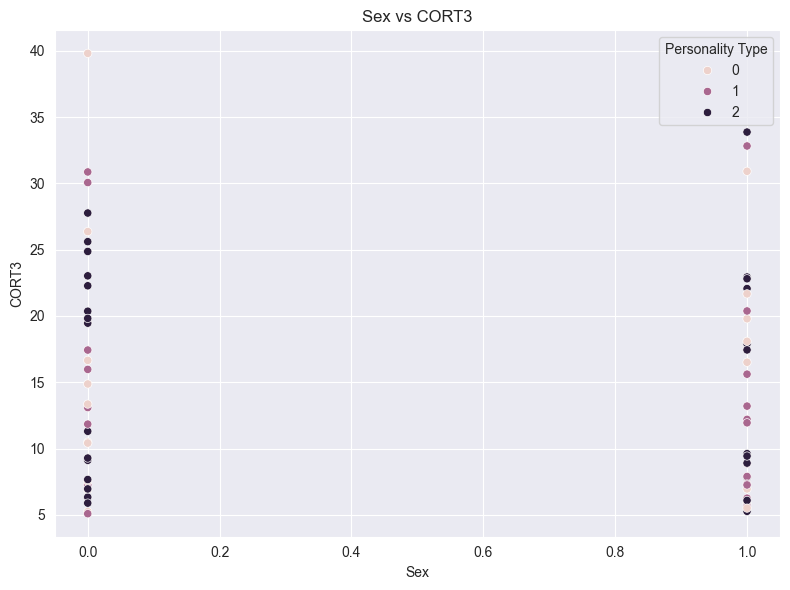

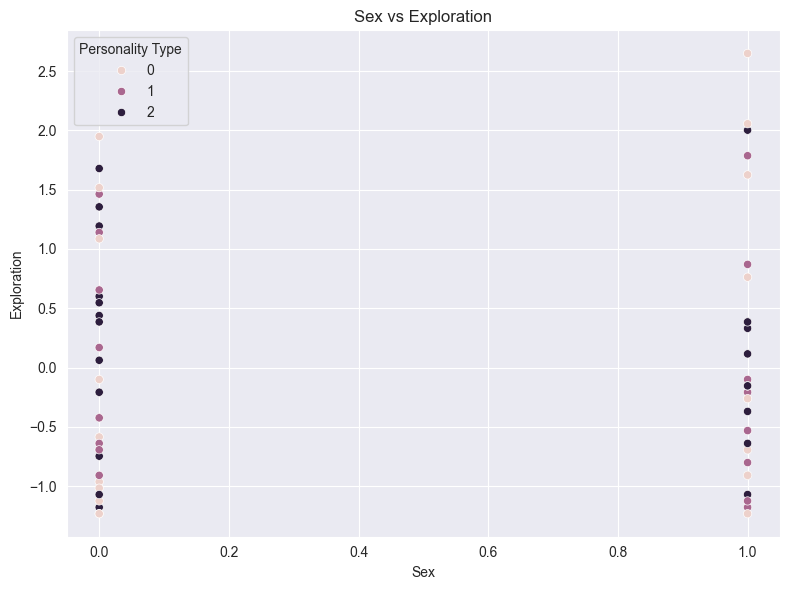

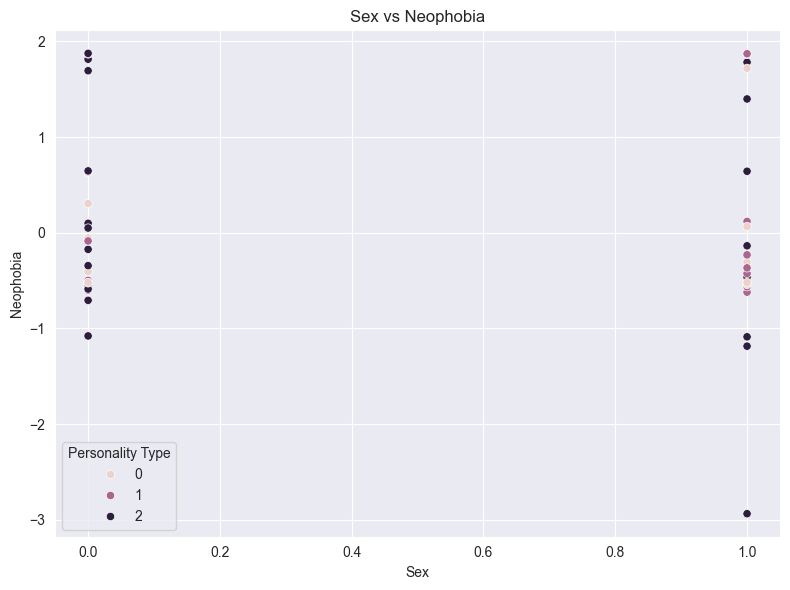

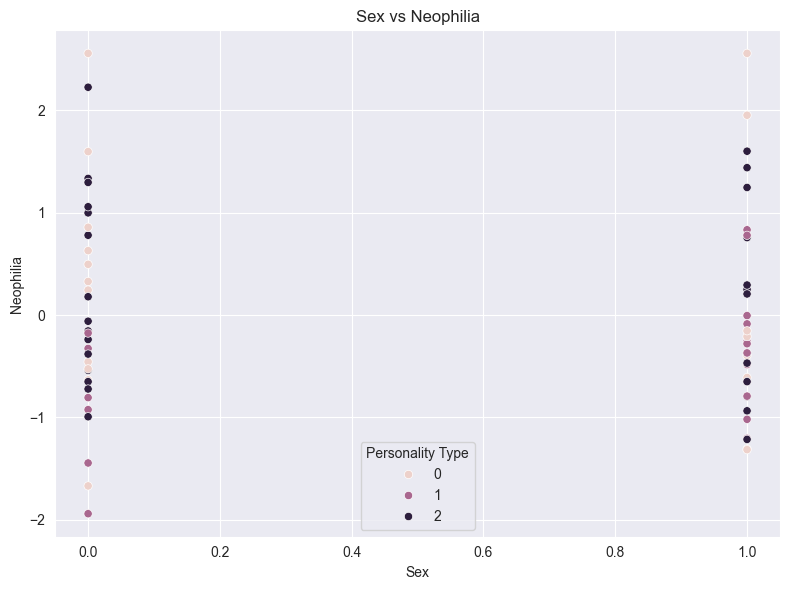

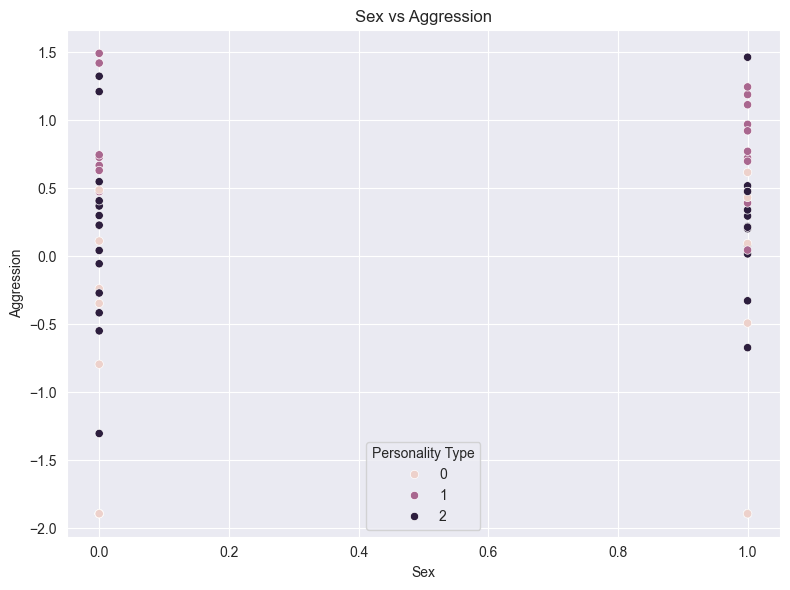

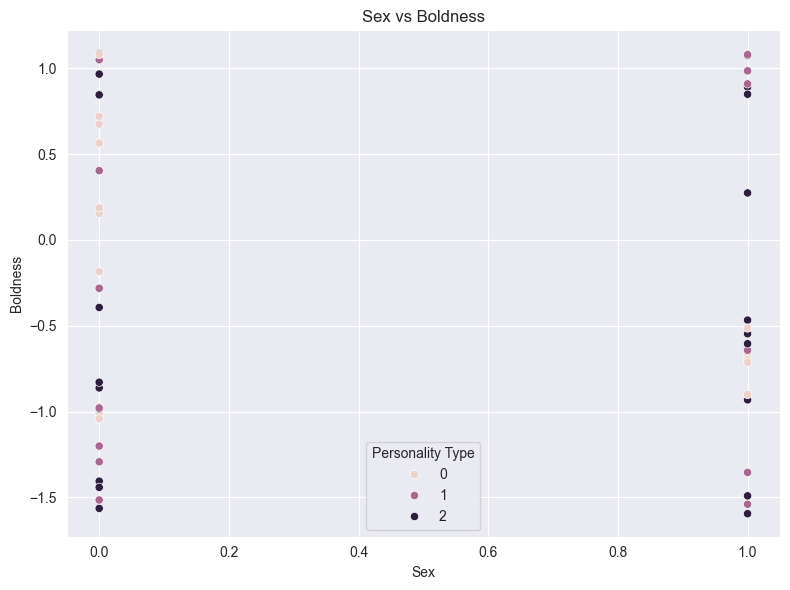

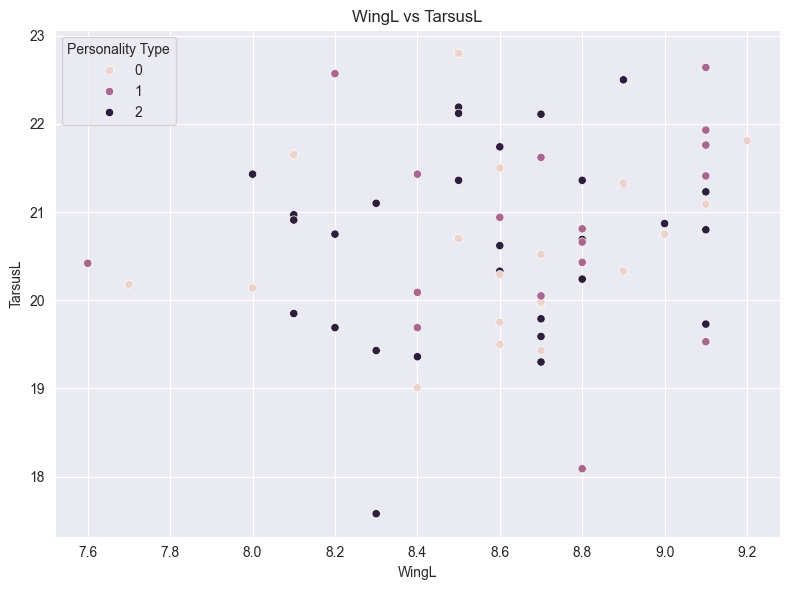

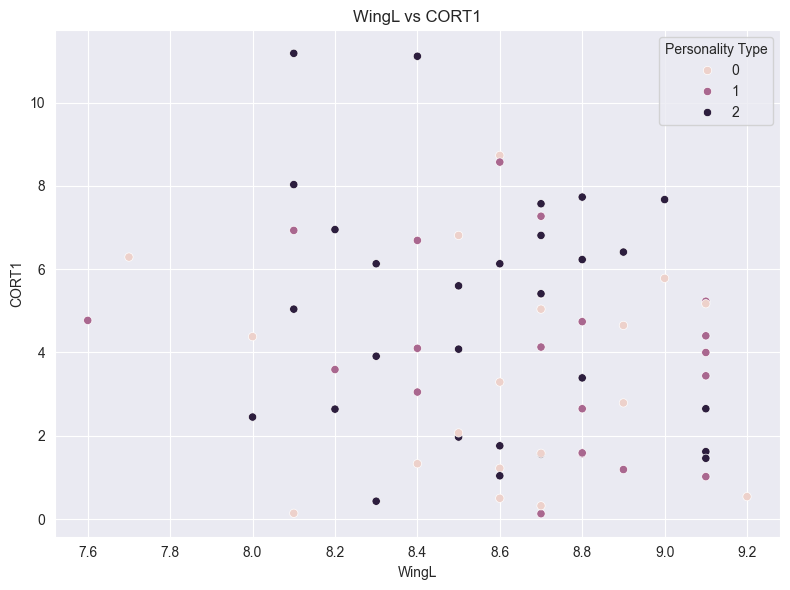

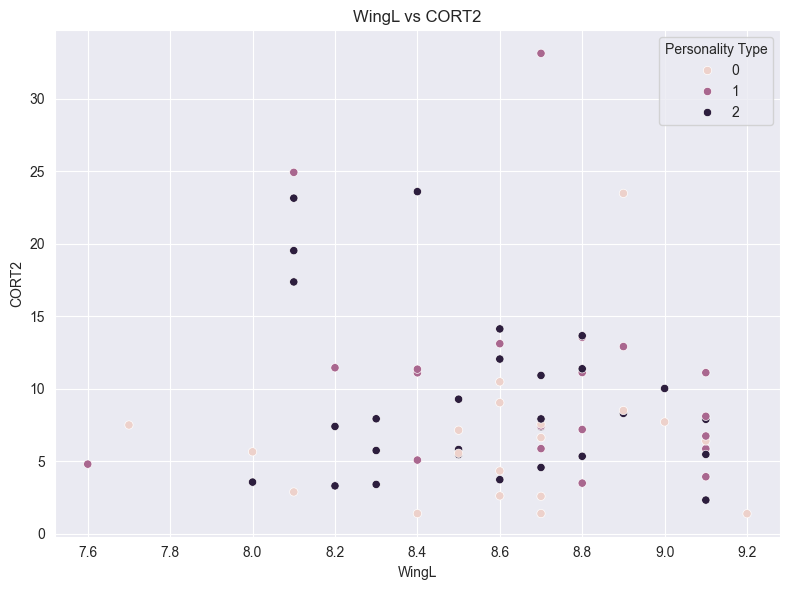

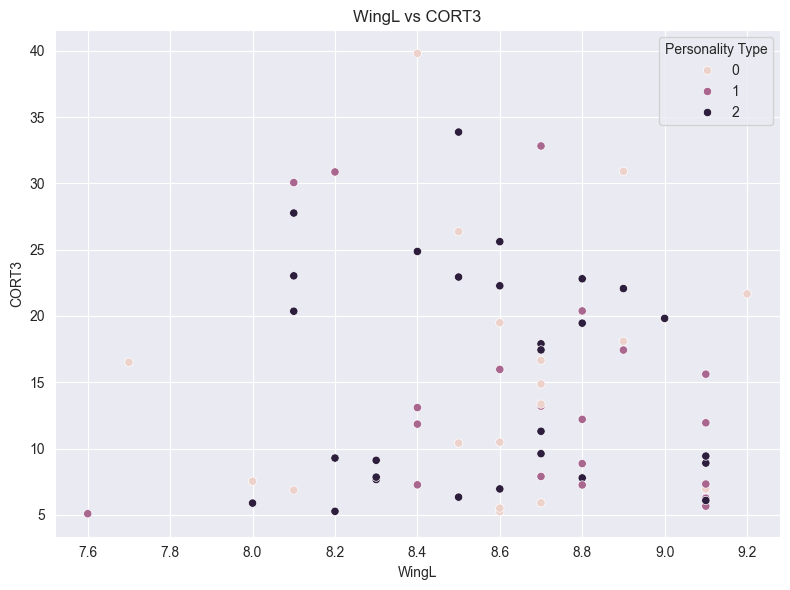

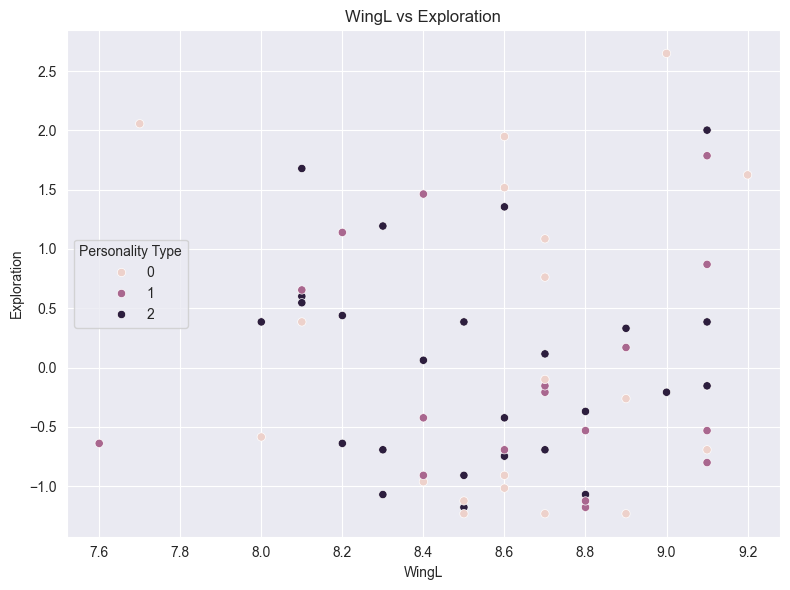

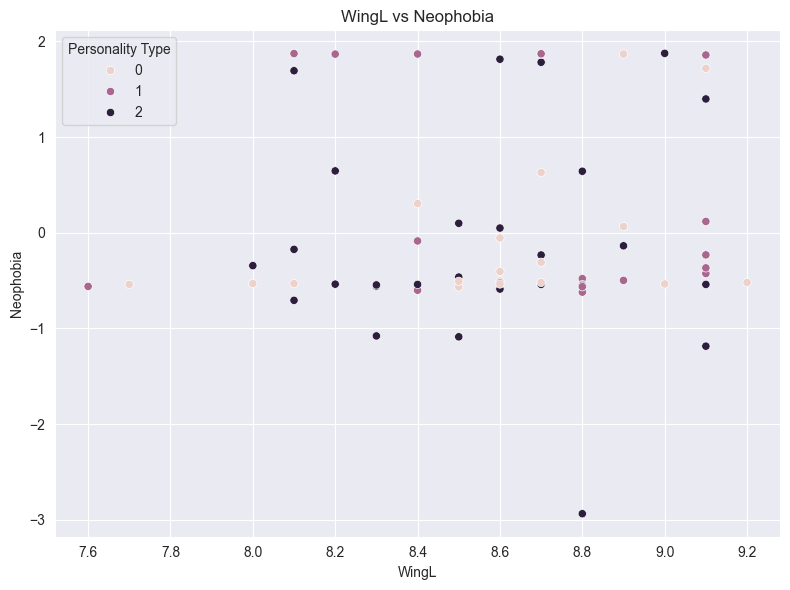

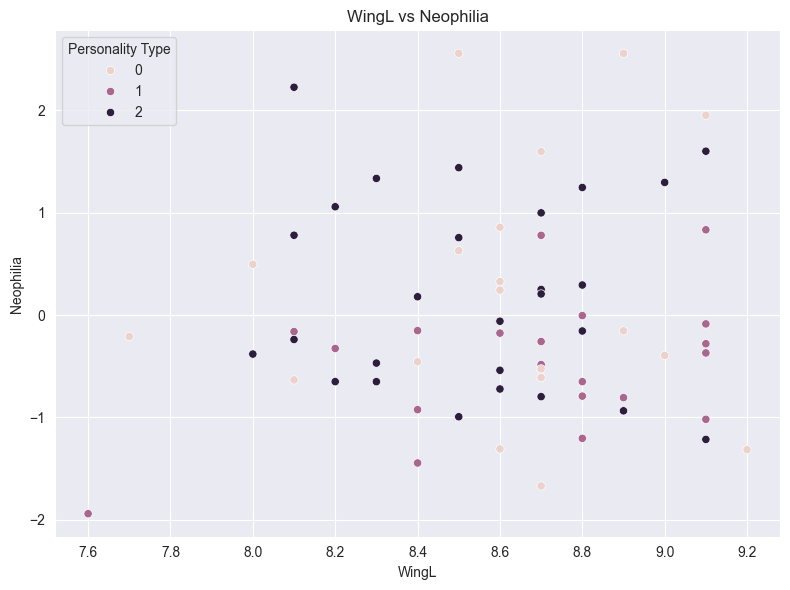

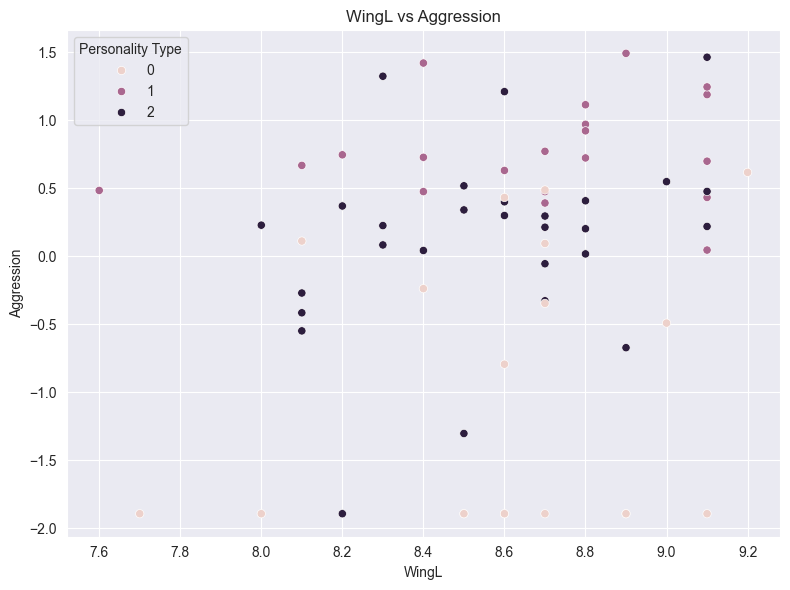

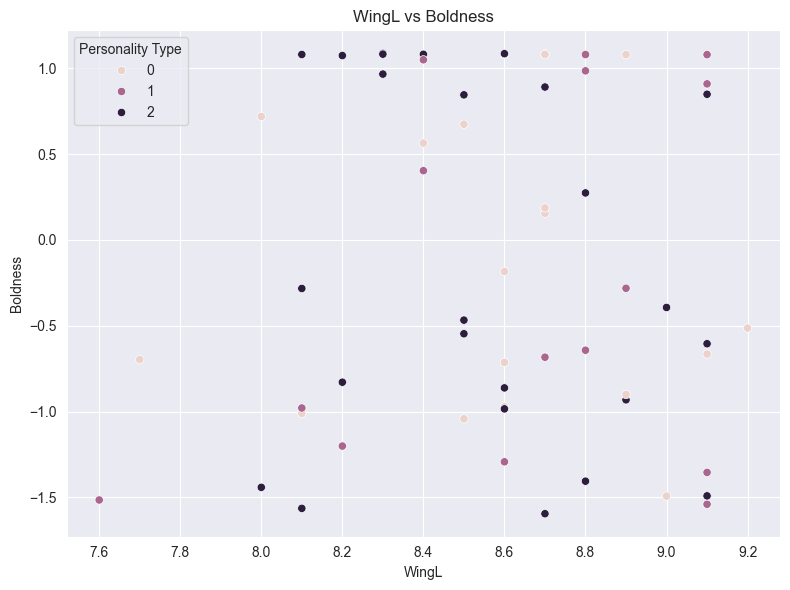

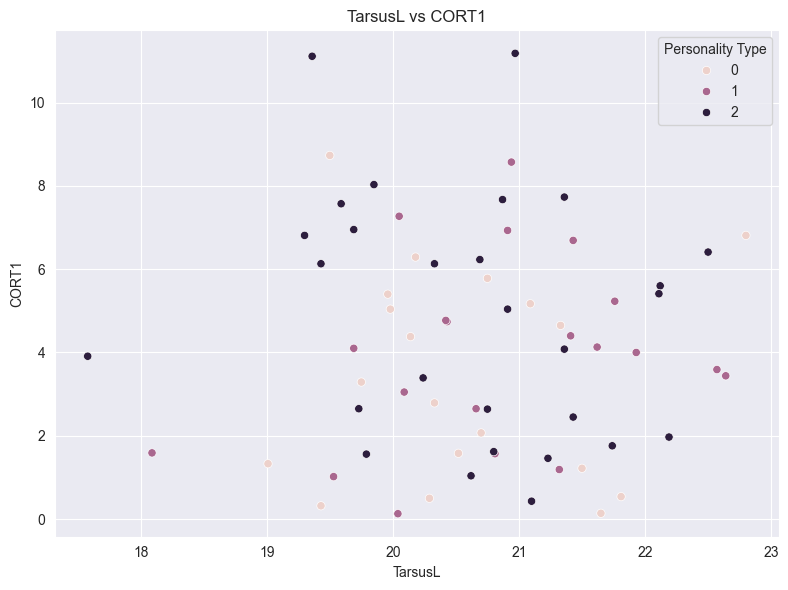

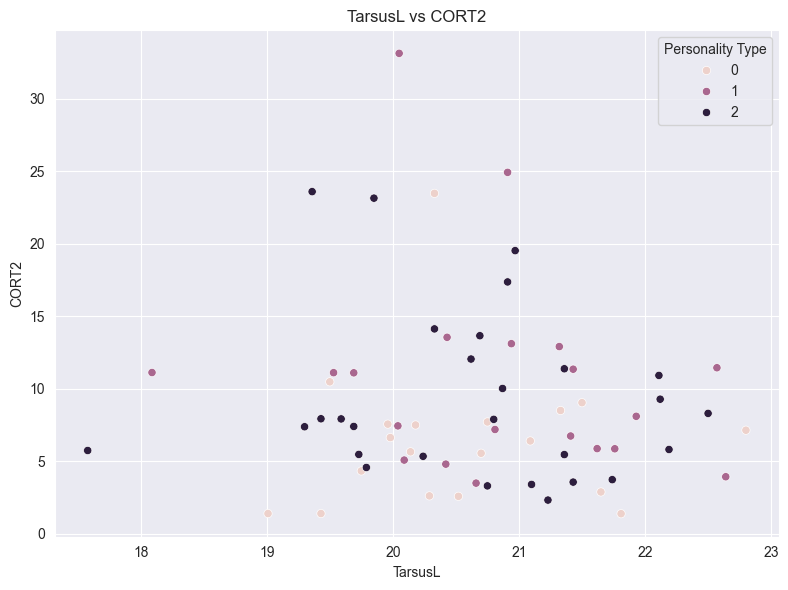

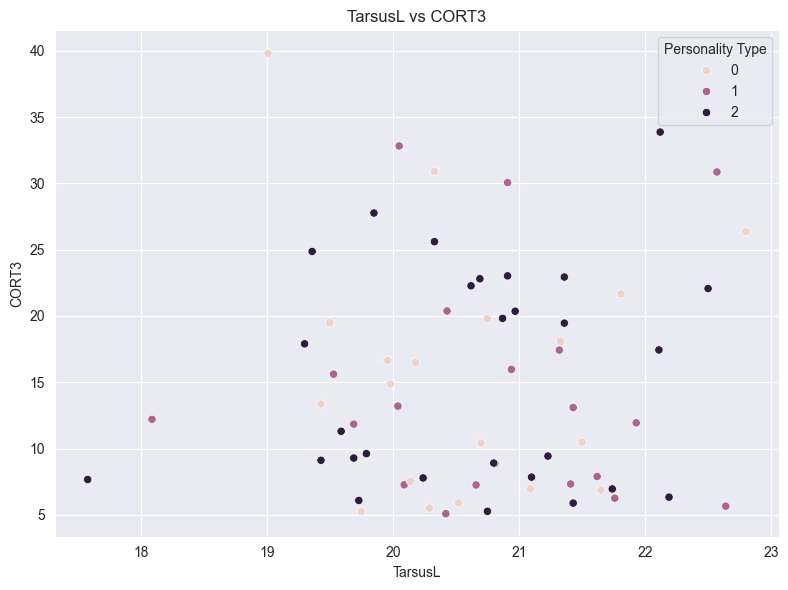

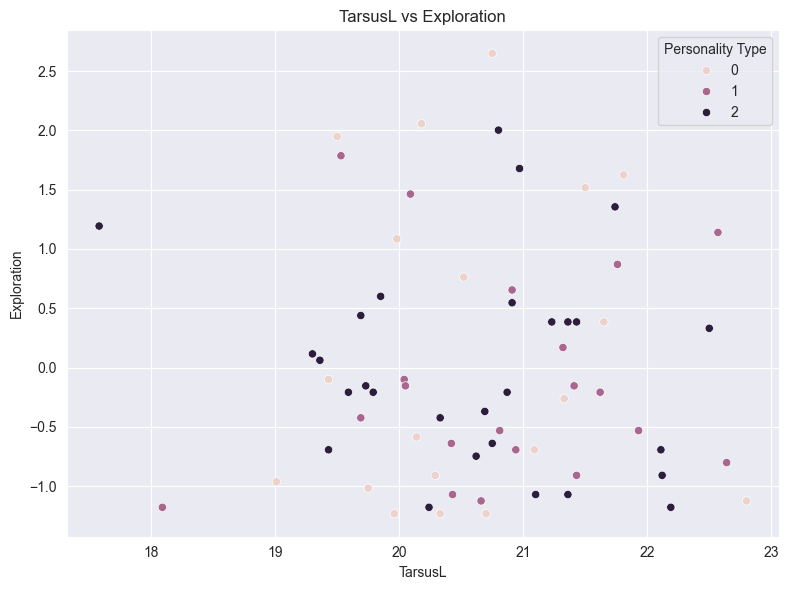

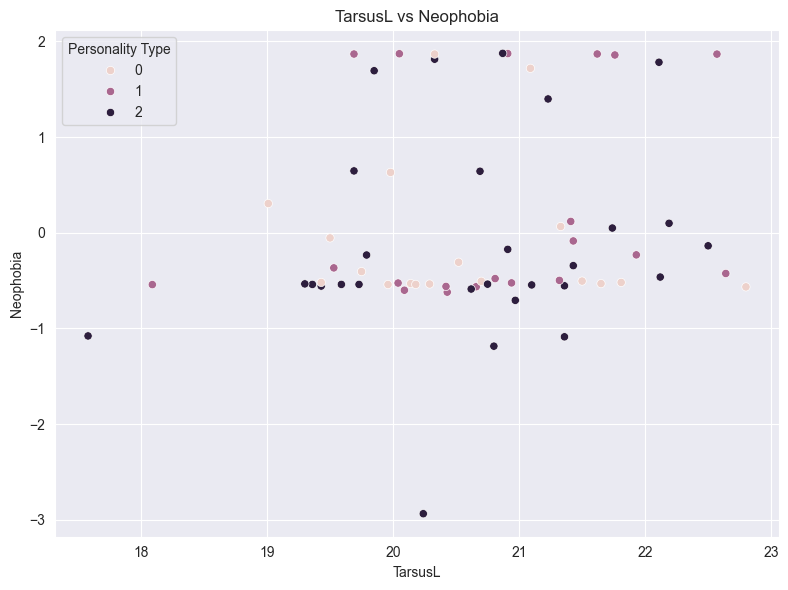

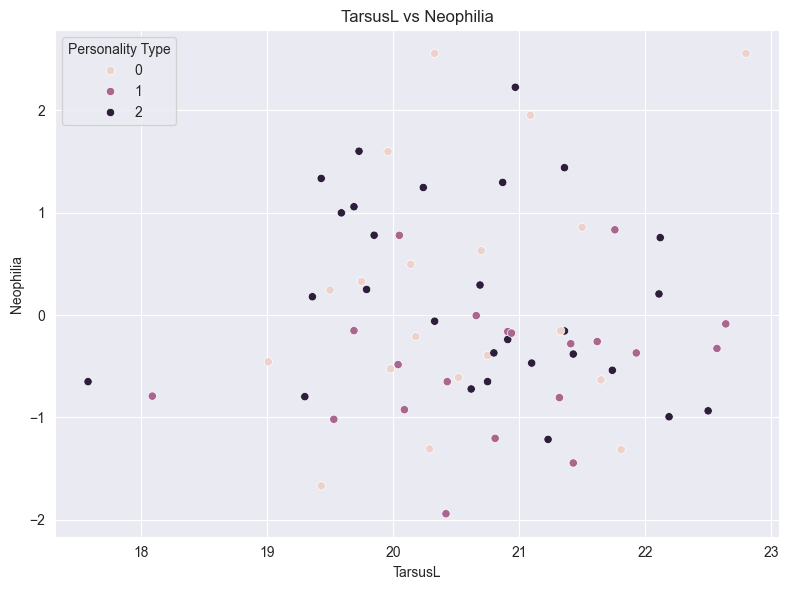

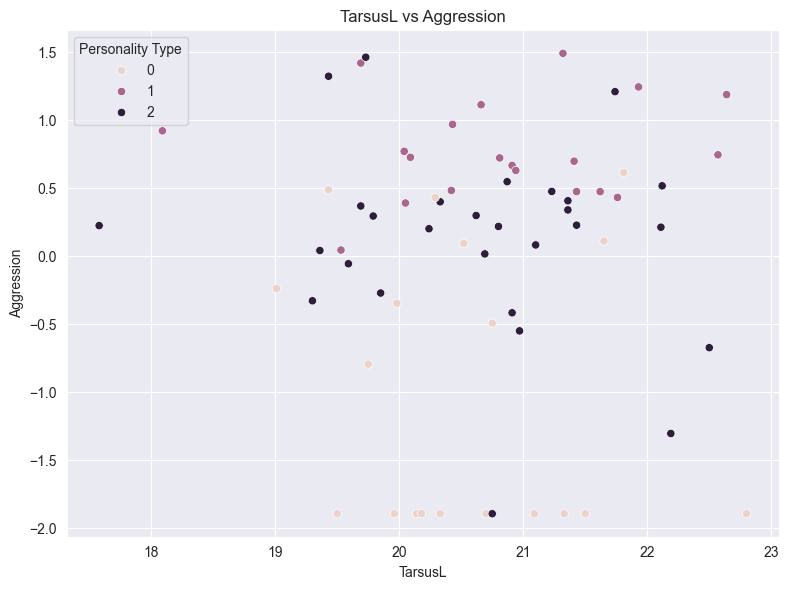

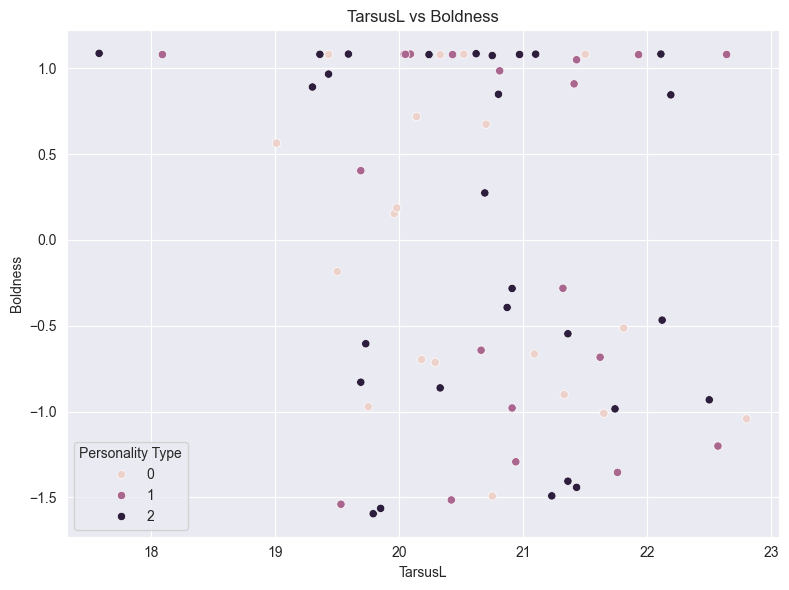

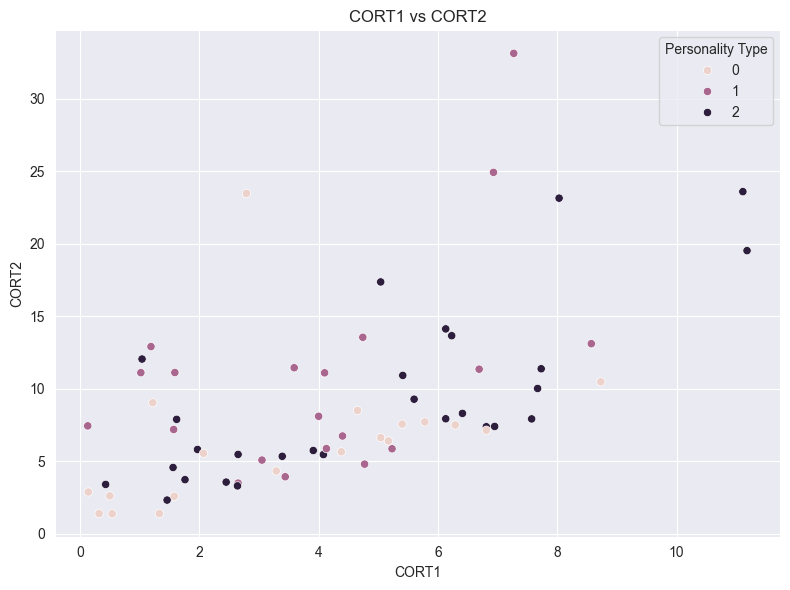

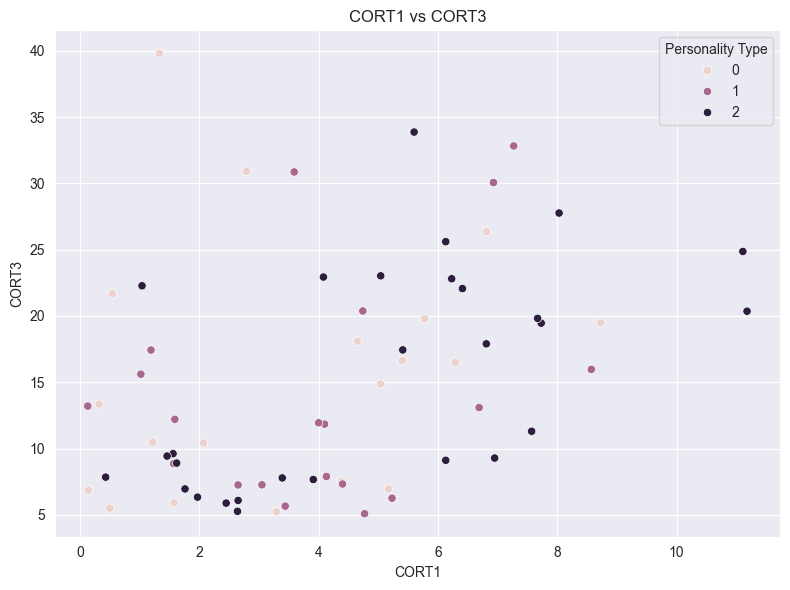

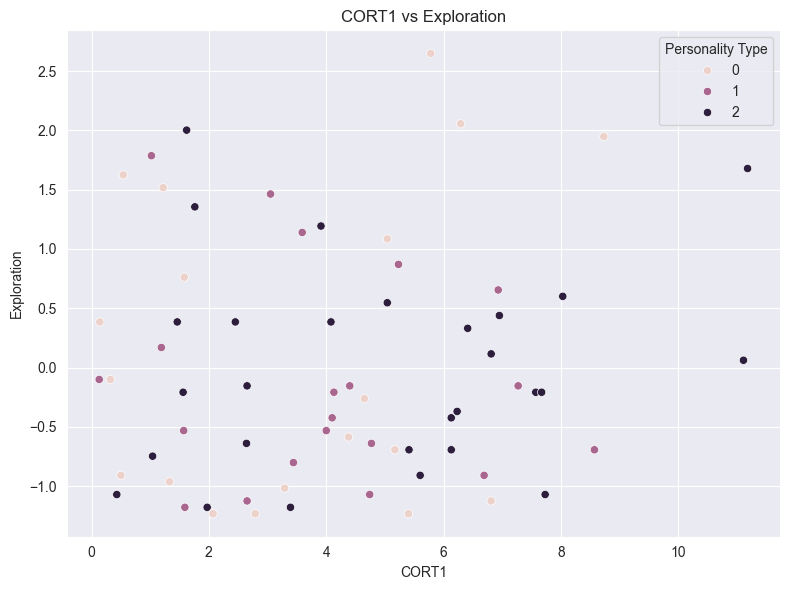

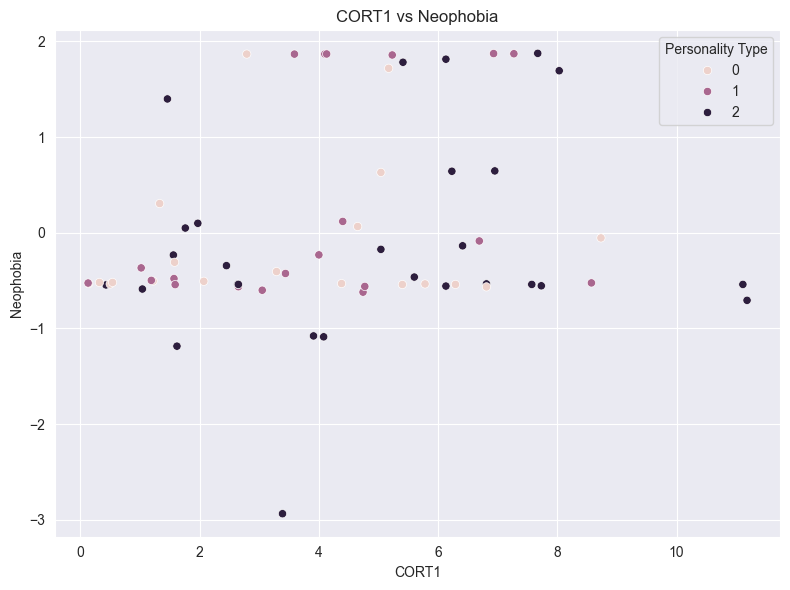

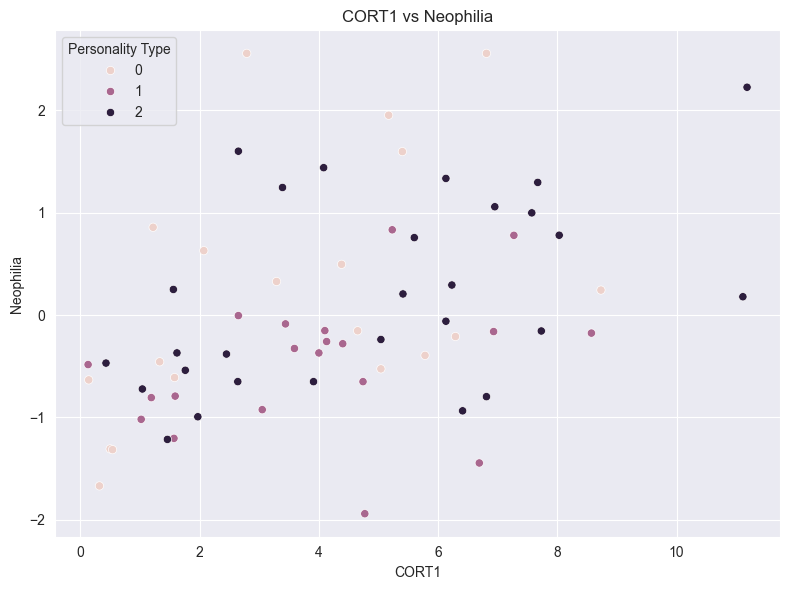

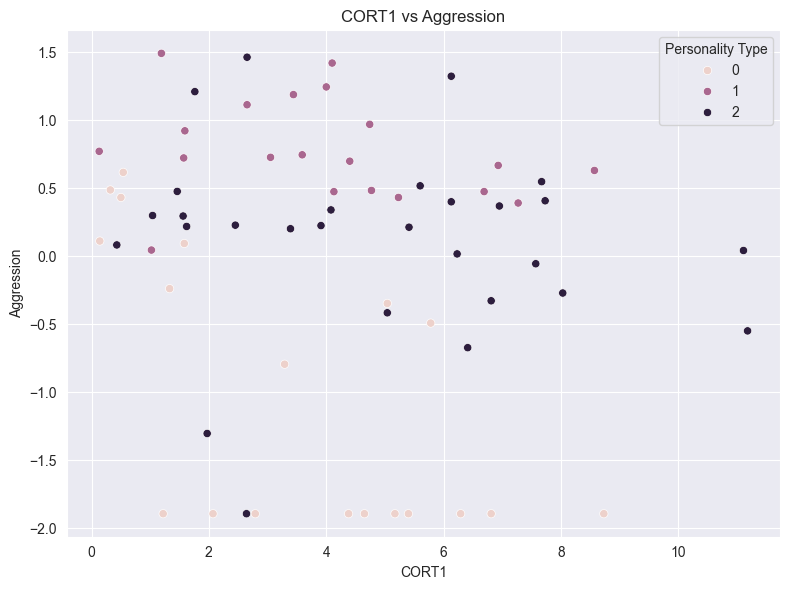

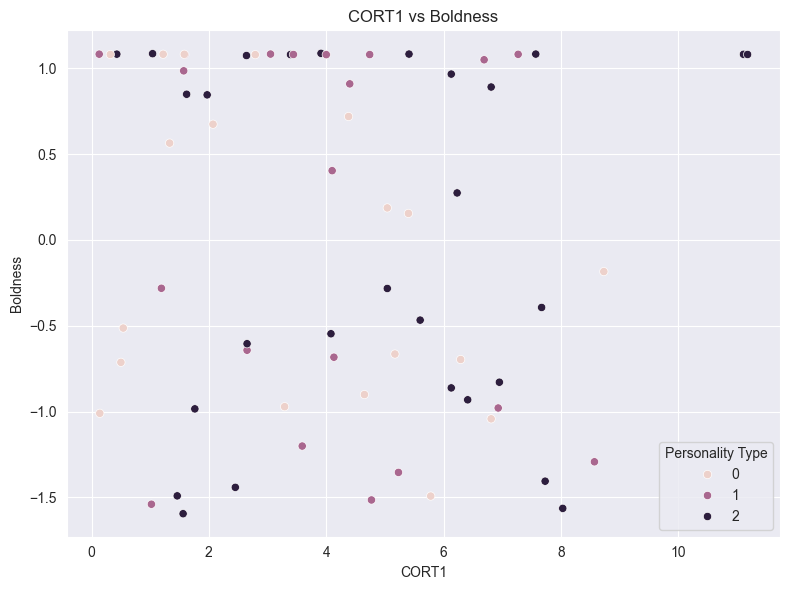

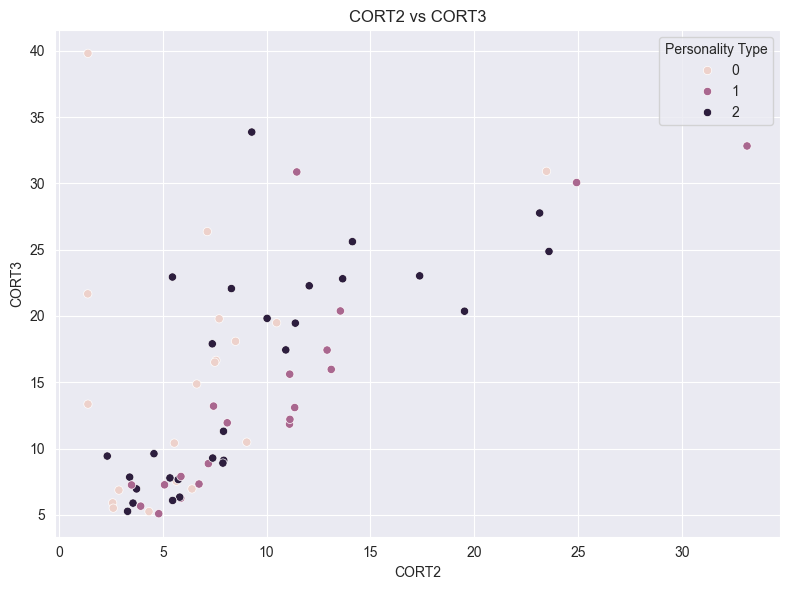

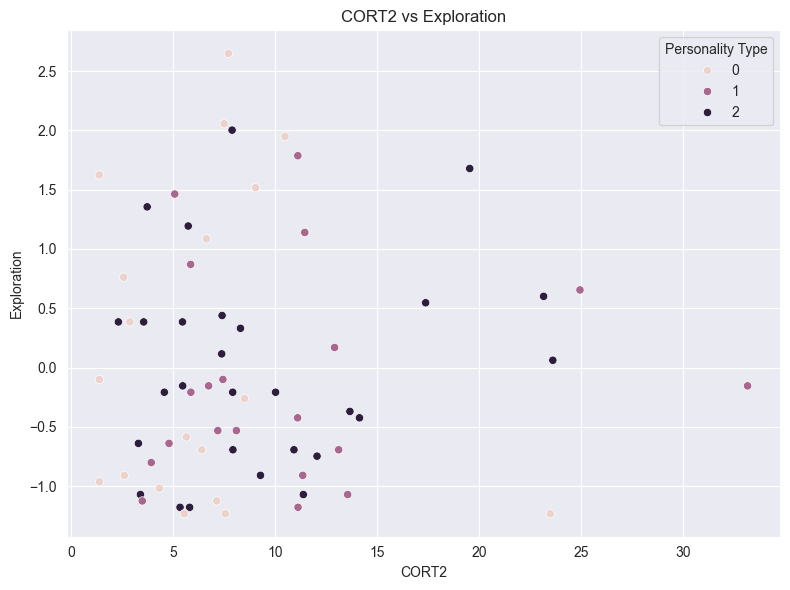

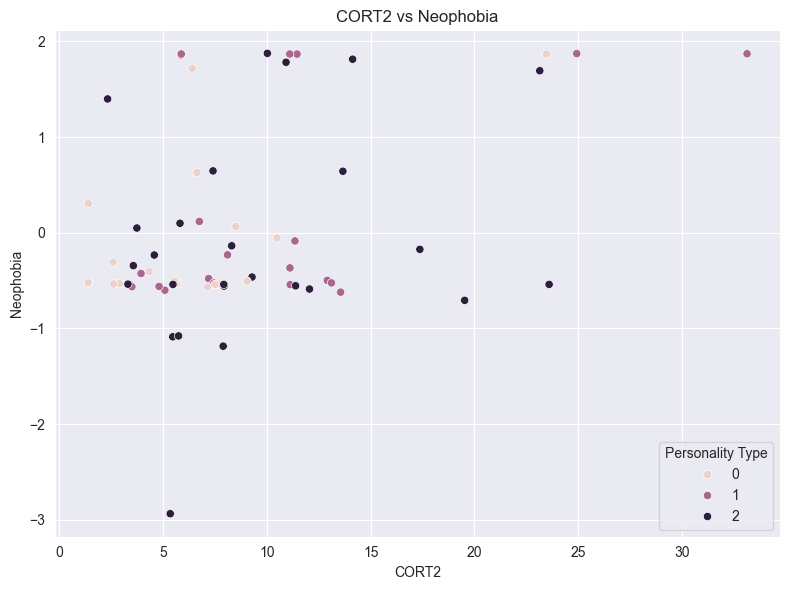

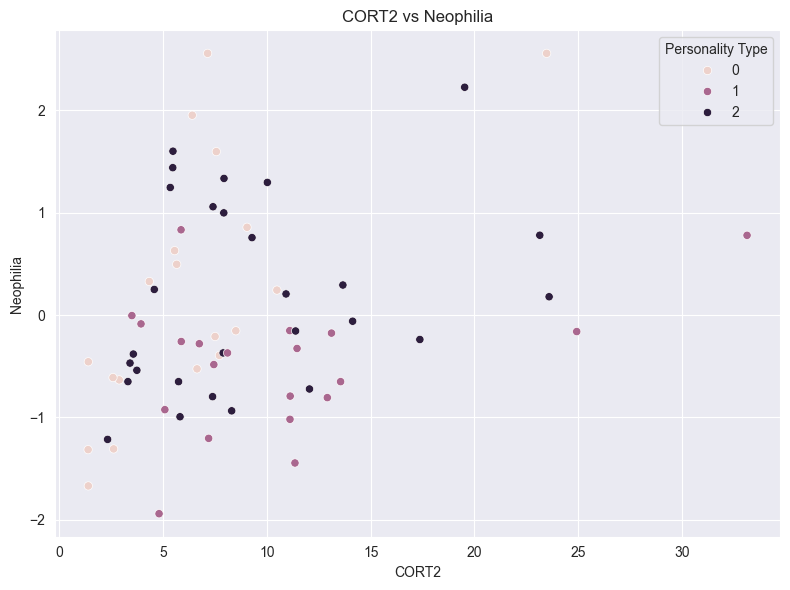

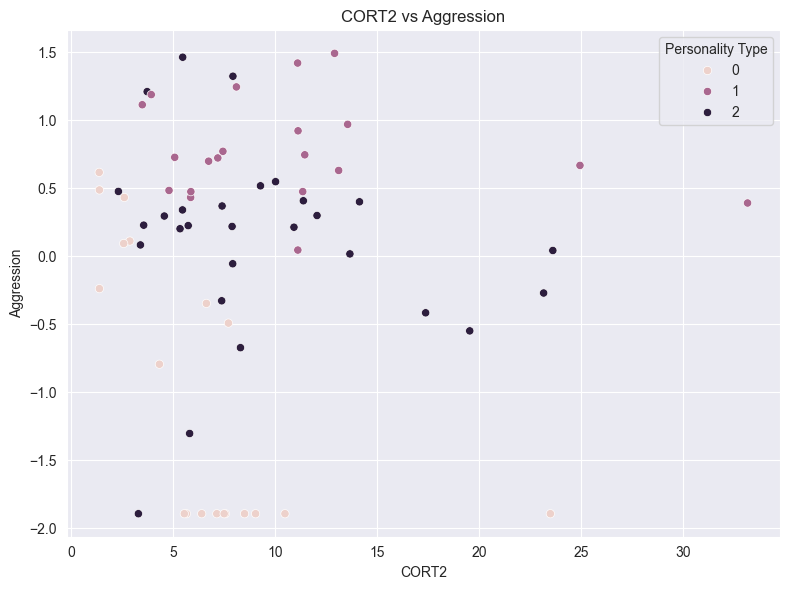

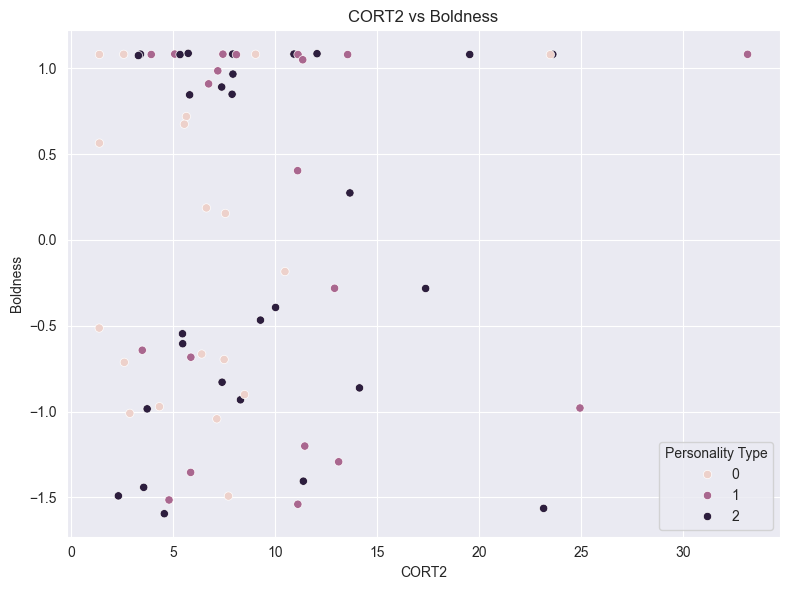

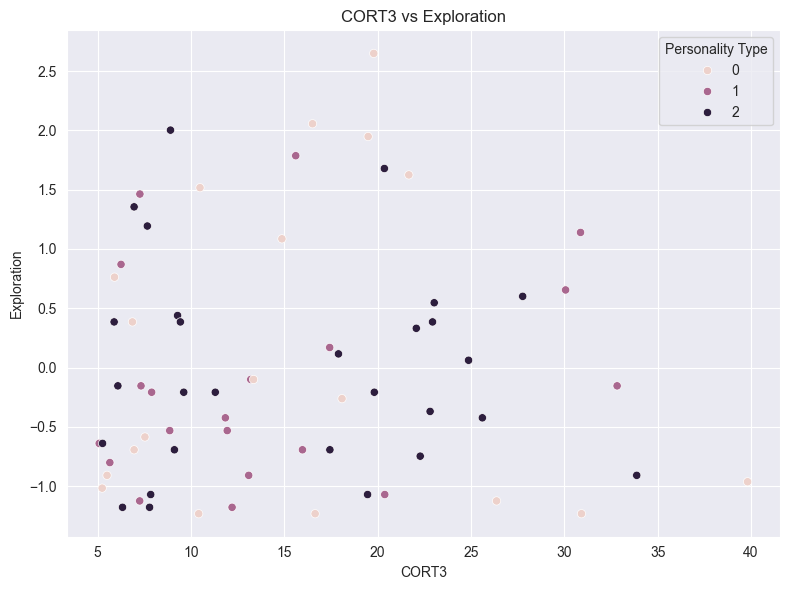

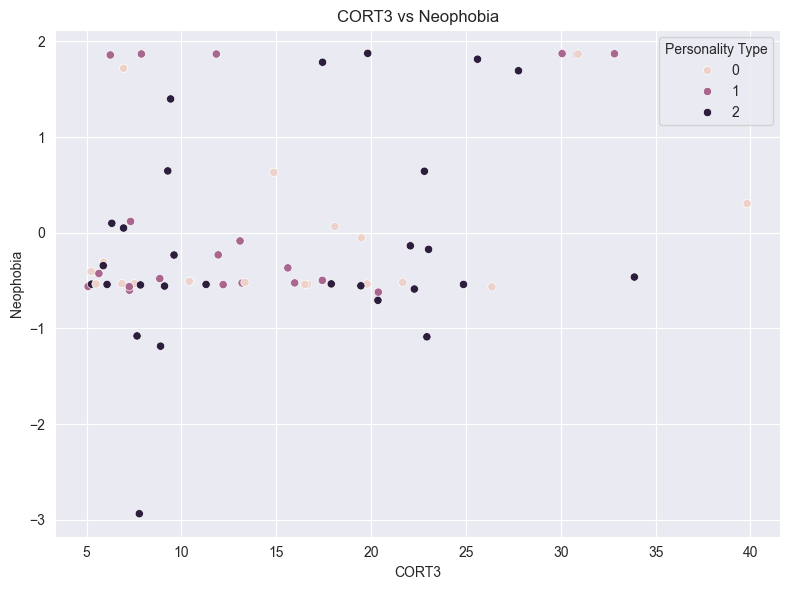

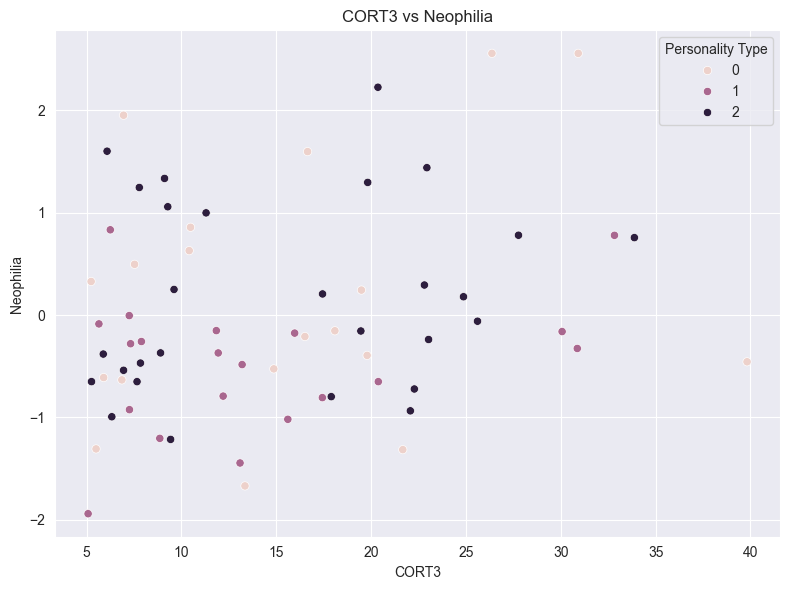

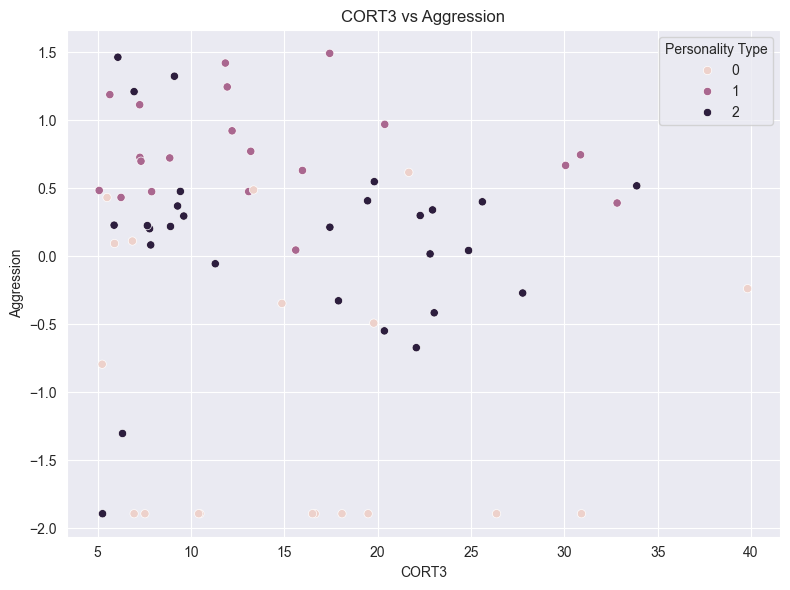

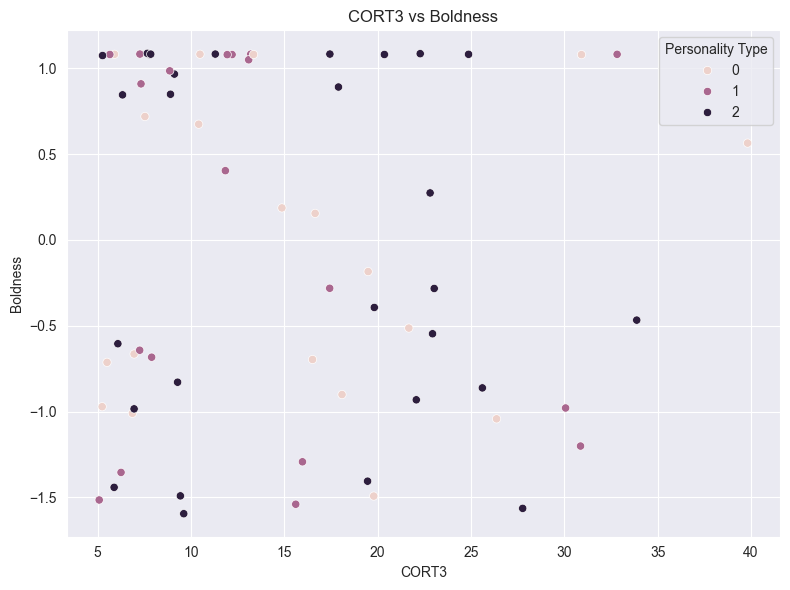

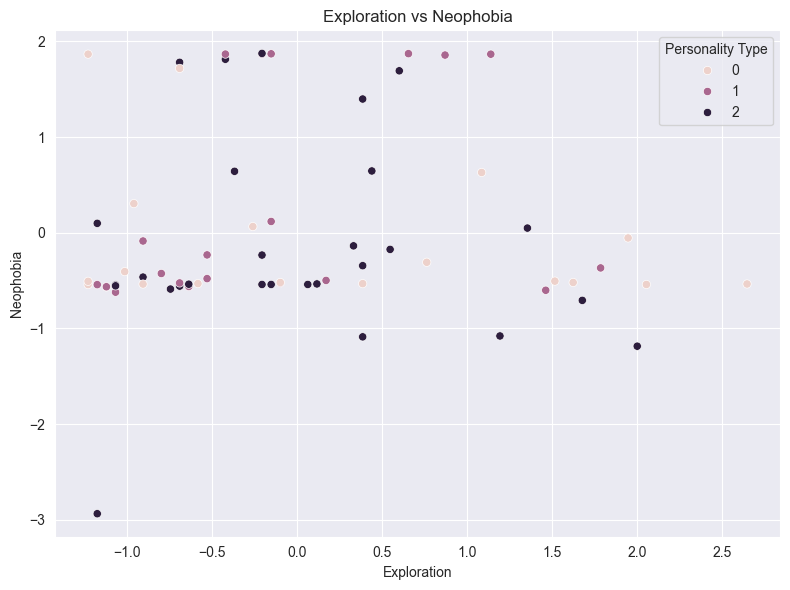

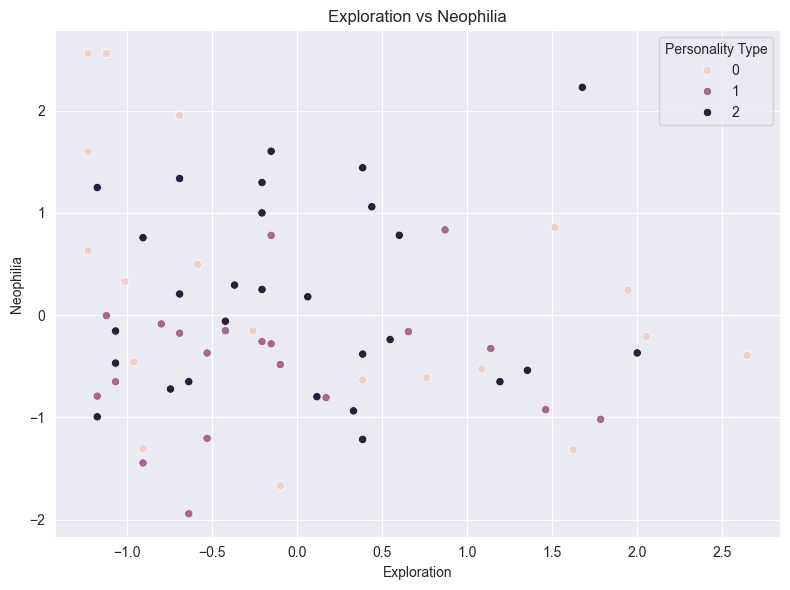

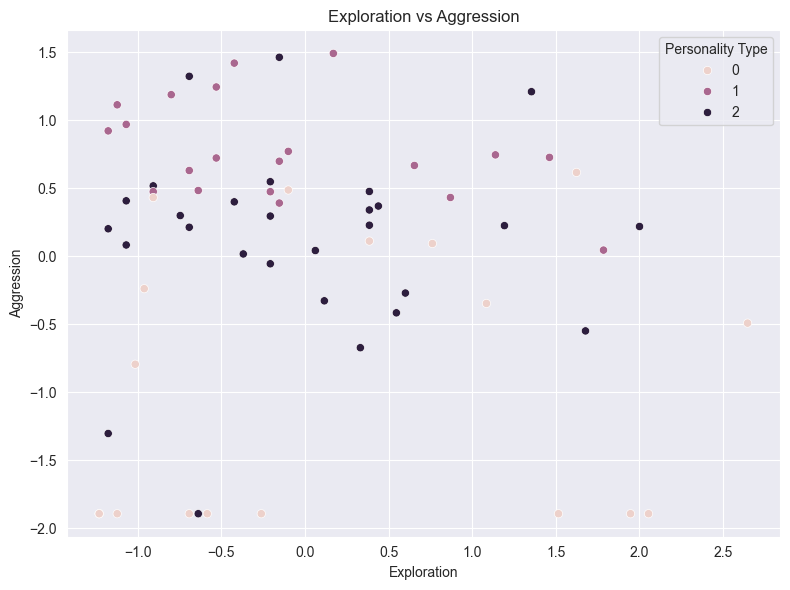

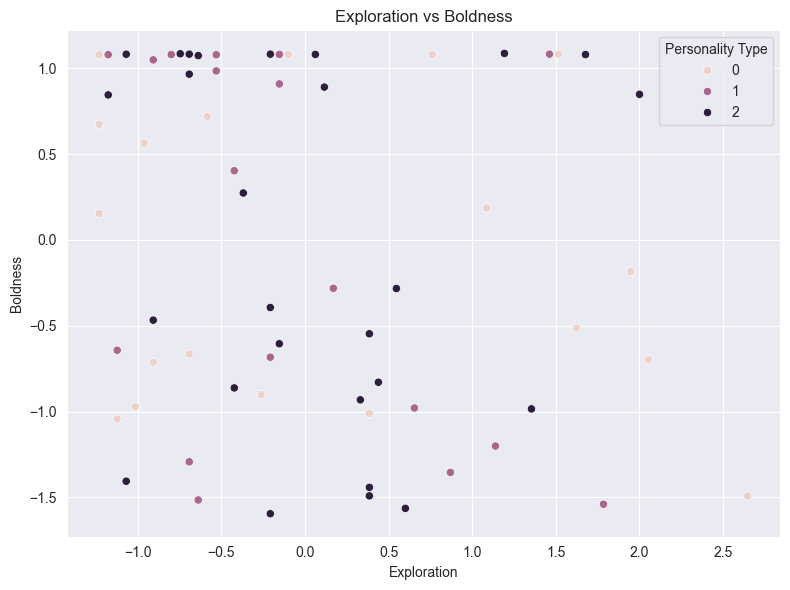

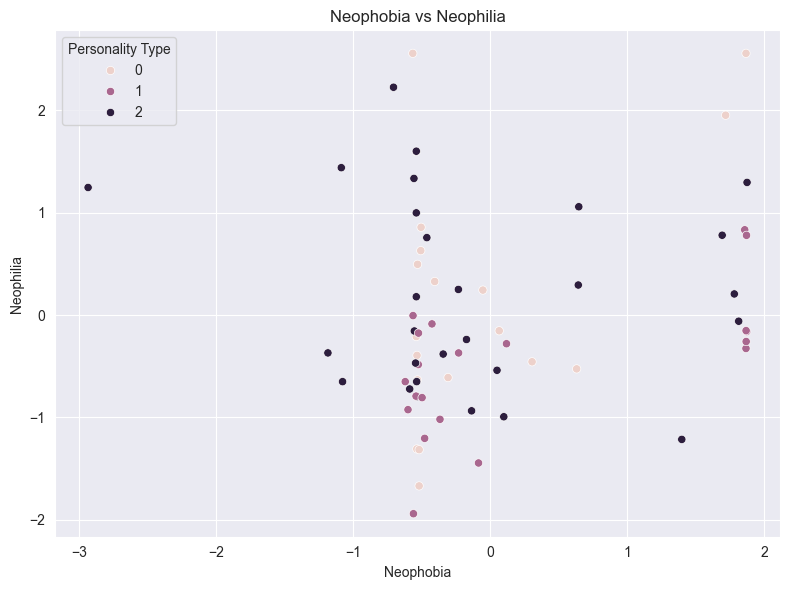

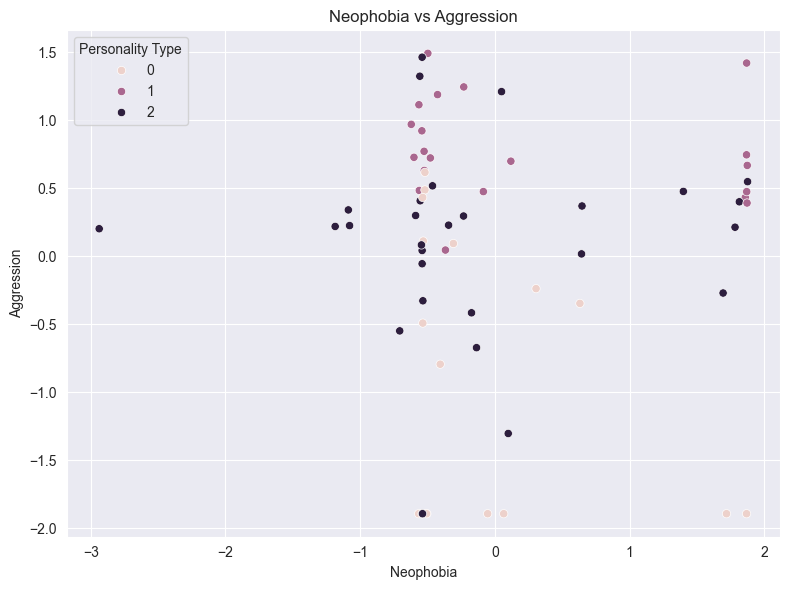

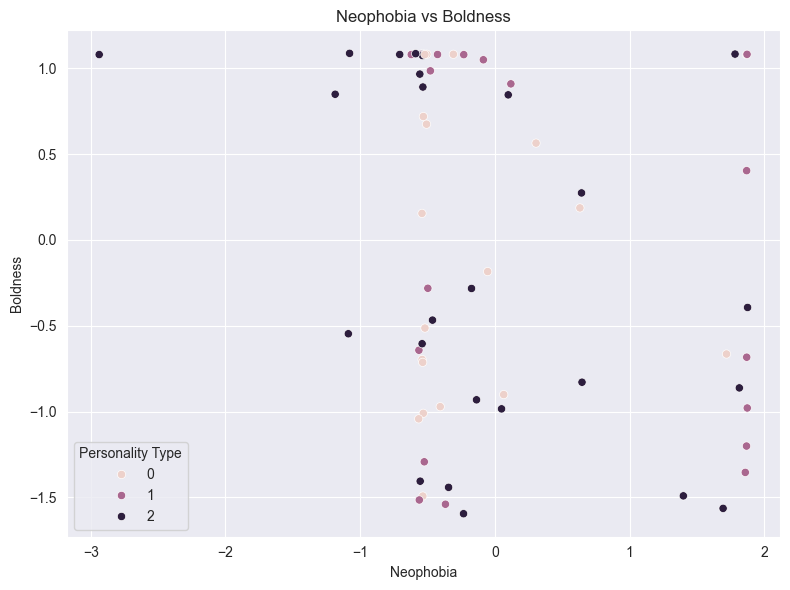

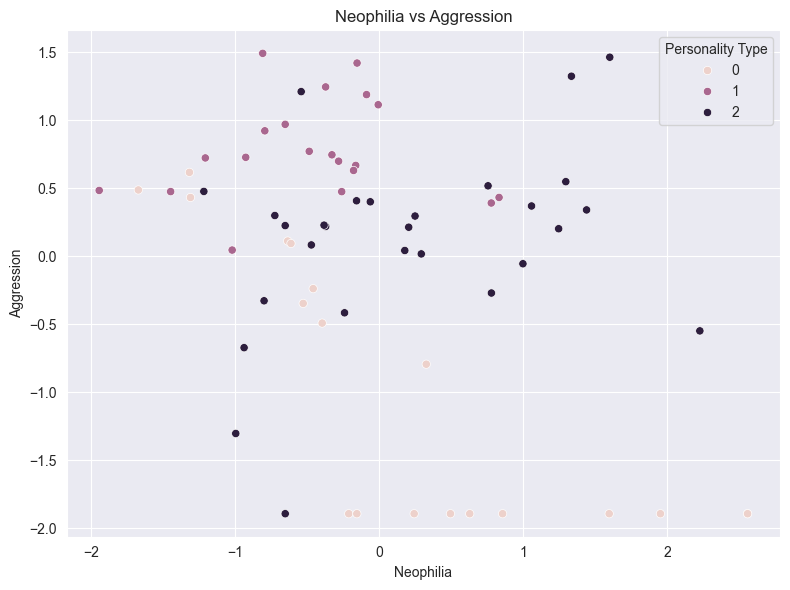

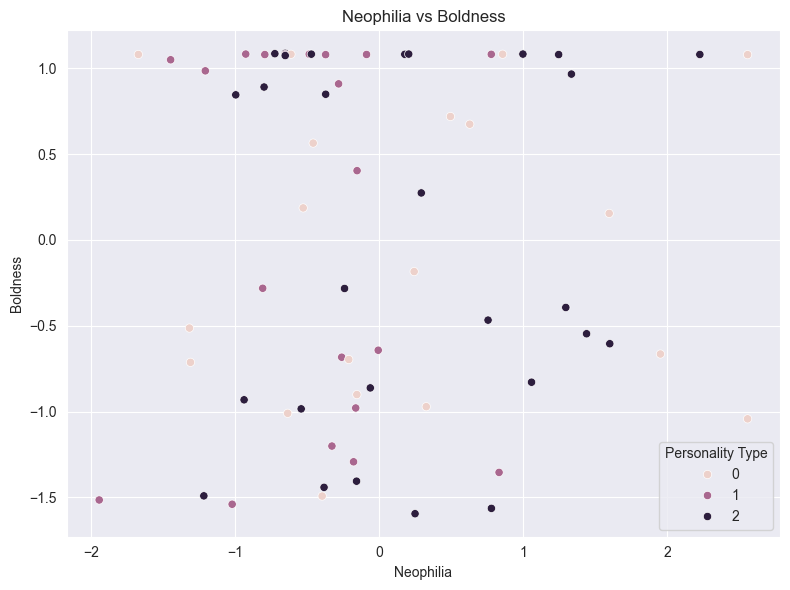

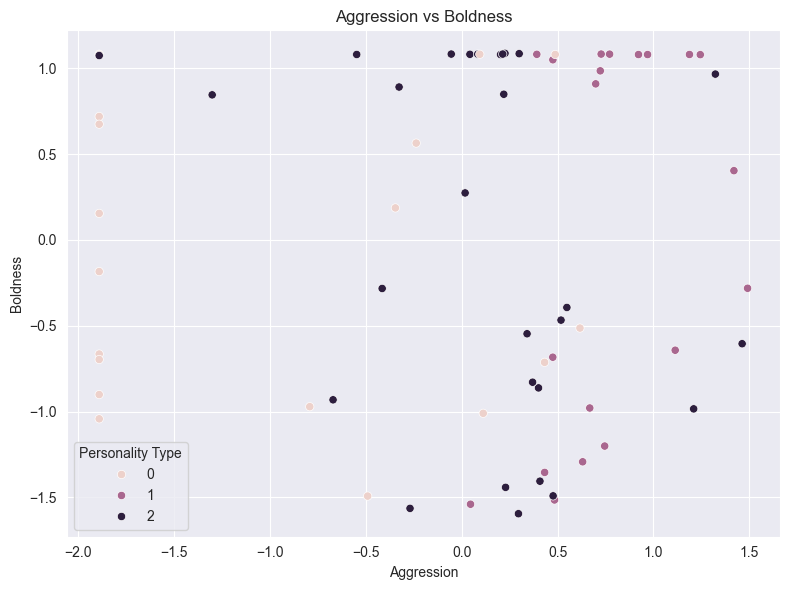

In [34]:
# Select the key variables for visualization
key_vars = ['Month', 'Weight', 'Sex', 'WingL', 'TarsusL', 'CORT1', 'CORT2', 'CORT3', 'Exploration', 'Neophobia', 'Neophilia', 'Aggression', 'Boldness']

# Create scatter plots for each pair of variables
for i in range(len(key_vars)):
    for j in range(i+1, len(key_vars)):
        plt.figure(figsize=(8, 6))
        sns.scatterplot(x=key_vars[i], y=key_vars[j], hue='Personality', data=df)
        plt.title(f"{key_vars[i]} vs {key_vars[j]}")
        plt.xlabel(key_vars[i])
        plt.ylabel(key_vars[j])
        plt.legend(title='Personality Type')
        plt.tight_layout()
        plt.show()

PCA

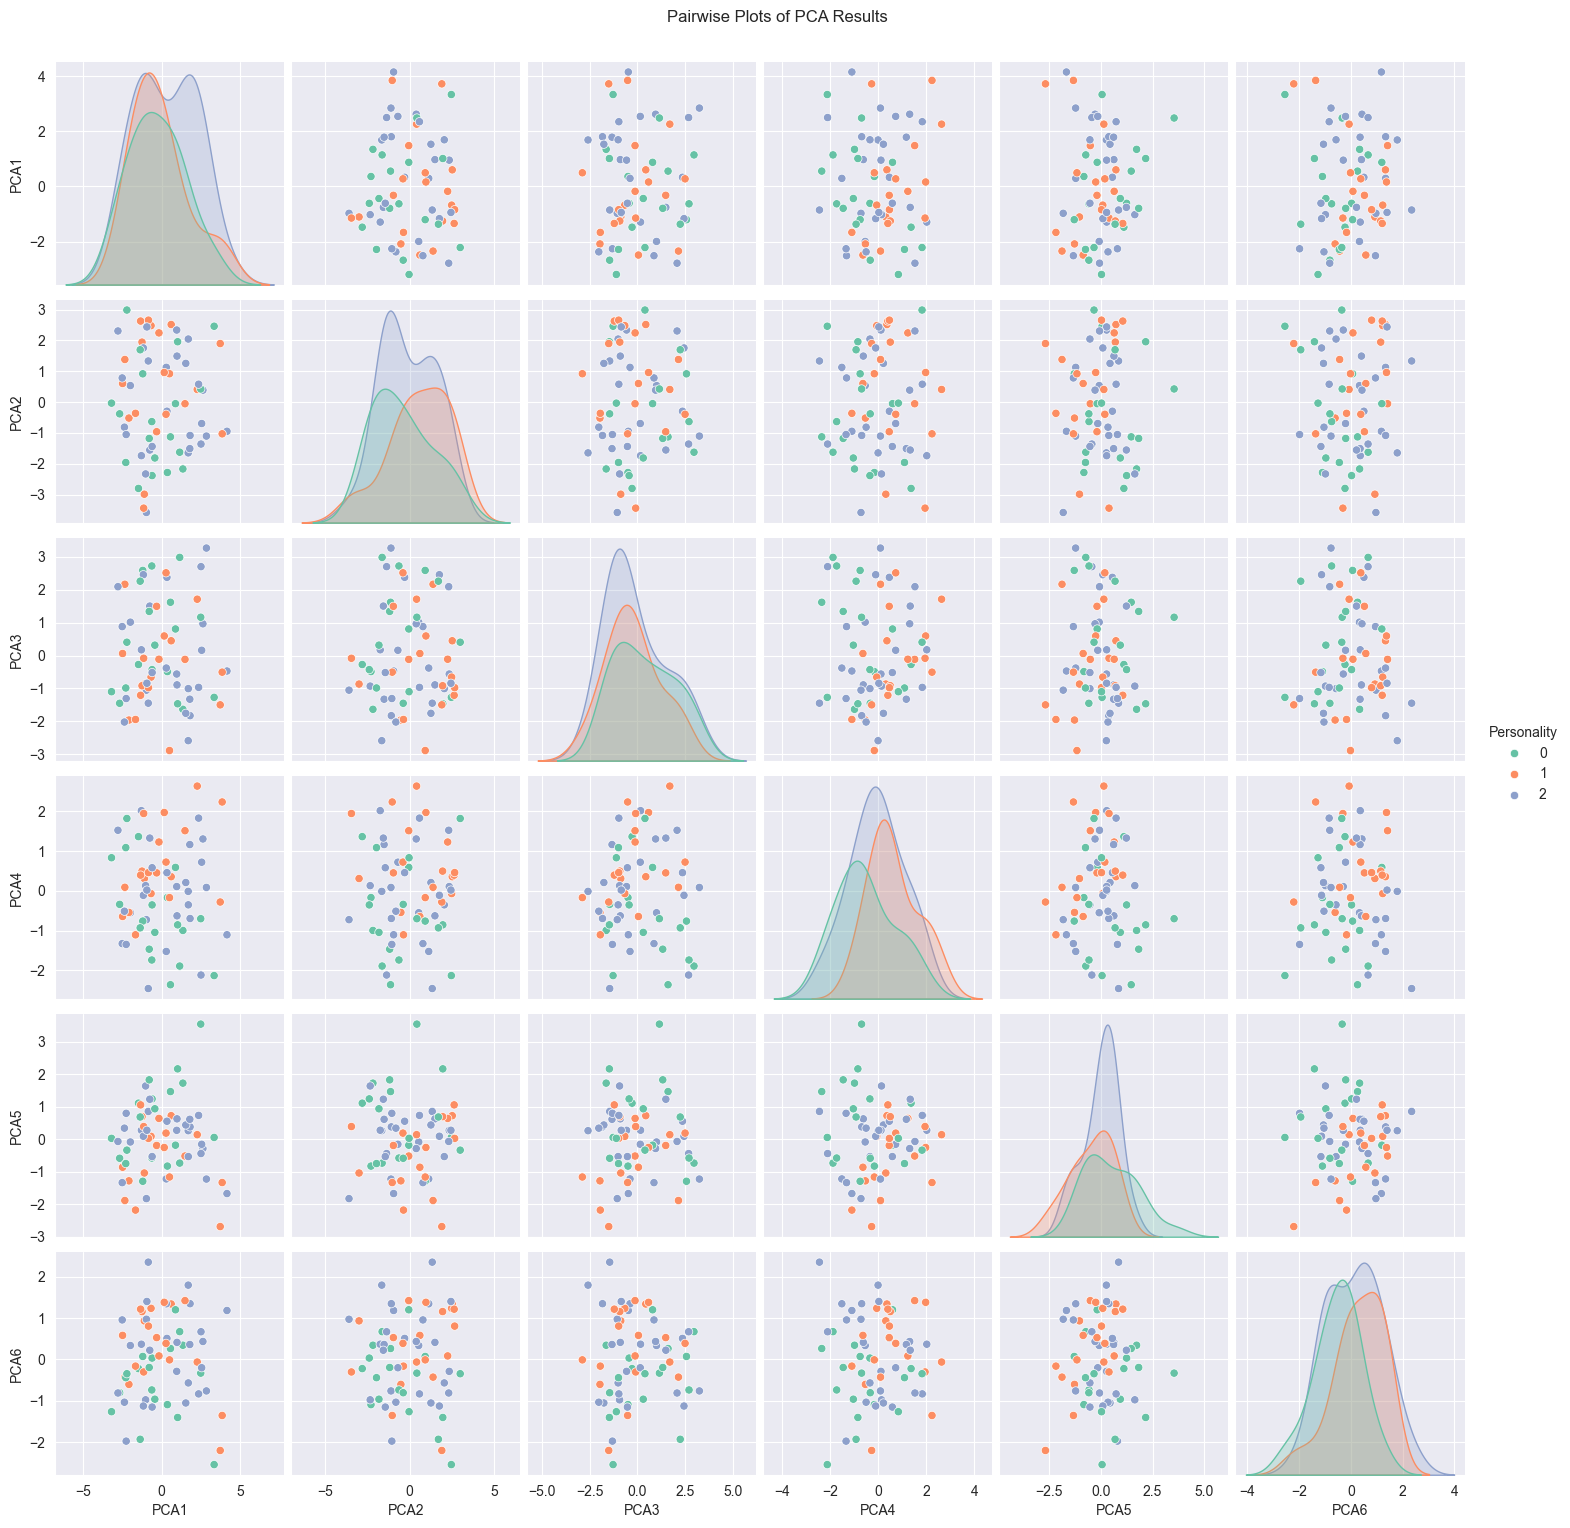

Explained variance by PCA components: [0.19584668 0.17204793 0.13437438 0.08220879 0.06960403 0.06183073]


In [35]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv('Angry+Birds+(Cardinal+Personalities)+Data+for+assignment.csv')

# Create a label encoder object
encoder = LabelEncoder()

# Encode categorical columns
df['Month'] = encoder.fit_transform(df['Month'])
df['Habitat'] = encoder.fit_transform(df['Habitat'])
df['Site'] = encoder.fit_transform(df['Site'])
df['Location'] = encoder.fit_transform(df['Location'])
df['Sex'] = encoder.fit_transform(df['Sex'])
df['Personality'] = encoder.fit_transform(df['Personality'])

# Select features for PCA (excluding the Personality column)
features = df.drop(columns=['Personality'])

# Standardize the data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Apply PCA with 6 components
pca = PCA(n_components=6)
pca_result = pca.fit_transform(scaled_features)

# Create a DataFrame with PCA results
pca_df = pd.DataFrame(data=pca_result, columns=[f'PCA{i+1}' for i in range(6)])
pca_df['Personality'] = df['Personality']

# Create pairwise plots of the PCA results
sns.pairplot(pca_df, hue='Personality', palette='Set2')
plt.suptitle('Pairwise Plots of PCA Results', y=1.02)
plt.show()

# Explained variance ratio
print(f'Explained variance by PCA components: {pca.explained_variance_ratio_}')

